In [45]:
from pathlib import Path
import pandas as pd
import numpy as np


import os
ROOT = Path(os.environ.get("MARKET_DATA_ROOT", str((Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()) / "data/market_data"))).expanduser()
MERGED = ROOT / 'merged_data'
FUT_FILE = ROOT / '国债期货合约数据/快照/30年TL合约/TL_main_snapshot.csv'
ETF_FILE = MERGED / '511090_20250701_20251231_merged.csv'
START, END = '2025-07-01', '2025-12-31'

# 读取数据并清洗

In [46]:
def load_futures():
    """读取 TL 主力连续合约快照并清洗"""
    cols = ['code', 'trade_time', 'last', 'pre_close', 'pre_settle',
            'volume', 'bid_price1', 'ask_price1']
    df = pd.read_csv(FUT_FILE, usecols=cols) 
    n0 = len(df)
    # 时间戳有带毫秒和不带毫秒两种格式, 必须用 ISO8601 解析
    df['trade_time'] = pd.to_datetime(df['trade_time'], format='ISO8601', errors='coerce')
    df = df.dropna(subset=['trade_time'])
    end_excl = pd.Timestamp(END) + pd.Timedelta(days=1)
    df = df[(df['trade_time'] >= START) & (df['trade_time'] < end_excl)]
    # 原文件不是按时间排序的
    df = df.sort_values('trade_time').drop_duplicates('trade_time', keep='last')

    # 只留交易时段; 下午保留到 15:15(期货收盘), 用来准确计算换月价差
    t = df['trade_time'].dt.time
    am = (t >= pd.Timestamp('09:30').time()) & (t <= pd.Timestamp('11:30').time())
    pm = (t >= pd.Timestamp('13:00').time()) & (t <= pd.Timestamp('15:15').time())
    df = df[am | pm]

    # 无效价格, 以及偏离昨结算价超过 3.5% 的异常值(TL 涨跌停幅度为 ±3.5%)
    df = df[(df['last'] > 0) & (df['bid_price1'] > 0) & (df['ask_price1'] > 0)]
    df = df[(df['last'] / df['pre_settle'] - 1).abs() <= 0.035]

    print(f'期货: 原始 {n0:,} 行 -> 清洗后 {len(df):,} 行, '
          f'{df["trade_time"].dt.date.nunique()} 个交易日')
    return df.reset_index(drop=True)

fut = load_futures()

期货: 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日


# 处理换月和分红的情况

In [47]:
def roll_table(fut):
    """找出主力合约切换的日期, 并计算换月价差 = 新合约昨收 - 旧合约昨收"""
    fut = fut.assign(date=fut['trade_time'].dt.normalize())
    daily = fut.groupby('date').agg(code=('code', 'first'),
                                    pre_close=('pre_close', 'first'),
                                    close=('last', 'last'))
    daily['prev_code'] = daily['code'].shift()
    daily['prev_close'] = daily['close'].shift()
    rolls = daily[(daily['code'] != daily['prev_code']) & daily['prev_code'].notna()].copy()
    # 换月日那行的 pre_close 是"新合约"前一天的收盘价, prev_close 是"旧合约"前一天的收盘价
    rolls['gap'] = rolls['pre_close'] - rolls['prev_close']
    return rolls[['prev_code', 'code', 'prev_close', 'pre_close', 'gap']]

def dividend_table(etf):
    """找出 ETF 除息日: 当日昨收价明显低于前一日实际收盘价, 差额即每份分红"""
    etf = etf.assign(date=etf['trade_time'].dt.normalize())
    daily = etf.groupby('date').agg(pre_close=('pre_close', 'first'), close=('last', 'last'))
    daily['prev_close'] = daily['close'].shift()
    daily['div'] = daily['prev_close'] - daily['pre_close']
    return daily.loc[daily['div'].abs() > 0.1, ['prev_close', 'pre_close', 'div']]

etf = pd.read_csv(ETF_FILE, parse_dates=['trade_time'])
rolls = roll_table(fut)
divs = dividend_table(etf)
display(rolls, divs)

,prev_code,code,prev_close,pre_close,gap
date,,,,,
2025-08-20,TL2509.CFE,TL2512.CFE,116.54,116.06,-0.48
2025-11-24,TL2512.CFE,TL2603.CFE,115.57,115.37,-0.20


,prev_close,pre_close,div
date,,,
2025-12-01,118.15,116.642,1.508


In [48]:
def back_adjust(dates, events, col):
    """向后复权: 对每个事件, 把事件日之前的所有行加上该事件的调整量"""
    adj = pd.Series(0.0, index=dates.index)
    for day, v in events[col].items():
        adj[dates < day] += v
    return adj

def build_pair(etf, fut, rolls, divs):
    """以 ETF 时间轴为基准配上期货, 生成复权价格和 ETF_Futures_Spread"""
    f = fut[['trade_time', 'code', 'last', 'bid_price1', 'ask_price1']].rename(columns={
        'code': 'fut_code', 'last': 'fut_last', 'bid_price1': 'fut_bid', 'ask_price1': 'fut_ask'})
    f['date'] = f['trade_time'].dt.normalize()
    f['fut_time'] = f['trade_time']

    out = etf.copy()
    out['date'] = out['trade_time'].dt.normalize()
    # 每个 ETF 时点取之前(含)最近的一条期货快照, 不跨日
    out = pd.merge_asof(out, f, on='trade_time', by='date', direction='backward')
    n0 = len(out)
    out = out.dropna(subset=['fut_last'])            # 12-31 没有期货数据, 会在这里去掉
    out['fut_stale_sec'] = (out['trade_time'] - out['fut_time']).dt.total_seconds()

    # 复权价格: 消除换月和分红造成的跳变
    out['fut_adj'] = out['fut_last'] + back_adjust(out['date'], rolls, 'gap')
    out['etf_adj'] = out['last'] - back_adjust(out['date'], divs, 'div')

    out['ETF_Futures_Spread_raw'] = out['last'] - out['fut_last']     # 未调整, 仅供对比
    out['ETF_Futures_Spread'] = out['etf_adj'] - out['fut_adj']       # 策略使用这一列

    print(f'ETF {n0:,} 行 -> 配上期货后 {len(out):,} 行, {out["date"].nunique()} 个交易日')
    return out.drop(columns=['date', 'fut_time']).reset_index(drop=True)

pair = build_pair(etf, fut, rolls, divs)

# 保存带价差列的合并数据
PAIR_FILE = MERGED / '511090_TL_20250701_20251231_merged.csv'
pair.to_csv(PAIR_FILE, index=False, date_format='%Y-%m-%d %H:%M:%S')

# 检查: 换月和除息前后, 调整后的价差应该是连续的
daily = pair.groupby(pair['trade_time'].dt.normalize())[
    ['ETF_Futures_Spread_raw', 'ETF_Futures_Spread']].last()
display(daily.loc['2025-08-15':'2025-08-22'].round(3),
        daily.loc['2025-11-19':'2025-12-03'].round(3))

ETF 604,853 行 -> 配上期货后 600,012 行, 125 个交易日


,ETF_Futures_Spread_raw,ETF_Futures_Spread
trade_time,,
2025-08-15,3.960,3.132
2025-08-18,3.818,2.990
2025-08-19,3.645,2.817
2025-08-20,4.140,2.832
2025-08-21,4.192,2.884
2025-08-22,4.138,2.830


,ETF_Futures_Spread_raw,ETF_Futures_Spread
trade_time,,
2025-11-19,3.386,2.078
2025-11-20,3.425,2.117
2025-11-21,3.470,2.162
2025-11-24,3.603,2.095
2025-11-25,3.492,1.984
2025-11-26,3.545,2.037
2025-11-27,3.625,2.117
2025-11-28,3.650,2.142
2025-12-01,2.197,2.197


# 参数估计

In [49]:
pair = pd.read_csv(MERGED / '511090_TL_20250701_20251231_merged.csv', parse_dates=['trade_time'])
def to_minute_bars(pair):
    """把 3 秒数据聚合成 1 分钟: 每分钟取最后一条快照, 时间标在这一分钟的结束时刻"""
    df = pair[['trade_time', 'last', 'fut_last', 'etf_adj', 'fut_adj', 'fut_code',
               'bid_price1', 'ask_price1', 'fut_bid', 'fut_ask', 'ETF_Futures_Spread']].copy()
    df = df.rename(columns={'last': 'etf_last', 'bid_price1': 'etf_bid', 'ask_price1': 'etf_ask',
                            'ETF_Futures_Spread': 'spread'})
    df['bar_time'] = df['trade_time'].dt.ceil('min')     # 09:30:01~09:31:00 归到 09:31
    bars = df.groupby('bar_time').last().drop(columns='trade_time')
    bars['date'] = bars.index.normalize()
    # 标记这一行和上一行是否在同一天(估计 OU 时用来剔除跨日的数据对)
    bars['same_day'] = bars['date'].eq(bars['date'].shift())
    return bars

bars = to_minute_bars(pair)
print(f'{len(bars):,} 根 1 分钟 K 线, {bars["date"].nunique()} 个交易日')
bars.head(3)


30,044 根 1 分钟 K 线, 125 个交易日


,etf_last,fut_last,etf_adj,fut_adj,fut_code,etf_bid,etf_ask,fut_bid,fut_ask,spread,date,same_day
bar_time,,,,,,,,,,,,
2025-07-01 09:31:00,124.351,120.46,122.843,119.78,TL2509.CFE,124.355,124.358,120.45,120.46,3.063,2025-07-01,False
2025-07-01 09:32:00,124.371,120.45,122.863,119.77,TL2509.CFE,124.372,124.373,120.44,120.45,3.093,2025-07-01,True
2025-07-01 09:33:00,124.366,120.45,122.858,119.77,TL2509.CFE,124.361,124.366,120.44,120.45,3.088,2025-07-01,True


In [50]:
def estimate_ou(x, same_day=None, dt=1.0):
    """
    估计 OU 过程 dX = θ(μ - X)dt + σ dW 的参数。

    方法: OU 过程的精确离散化是一阶自回归 X[t+1] = a·X[t] + b + ε, 其中
          a = exp(-θ·dt),  b = μ(1 - a),  Var(ε) = σ²(1 - a²)/(2θ)
    对它做最小二乘回归得到 a、b; 误差服从正态分布时, 这就是最大似然估计。

    参数:
      x        : 价差序列
      same_day : 与 x 等长的布尔数组, 表示该点与前一点是否同一天; 给出时剔除跨日的数据对
      dt       : 相邻两点的时间间隔(这里的单位是分钟)
    返回: theta(回归速度, 每分钟), mu(长期均值), sigma(扩散系数),
          sigma_eq(平稳标准差, 用于 z 分数), half_life(半衰期, 分钟), a, n
    """
    x = np.asarray(x, dtype=float)
    x0, x1 = x[:-1], x[1:]                      # 相邻的 (本期, 下期) 数据对
    if same_day is not None:
        keep = np.asarray(same_day, dtype=bool)[1:]
        x0, x1 = x0[keep], x1[keep]

    n = len(x0)
    nan = dict(theta=np.nan, mu=np.nan, sigma=np.nan, sigma_eq=np.nan,
               half_life=np.nan, a=np.nan, n=n)
    if n < 30:
        return nan

    # 最小二乘: x1 = a·x0 + b
    mx, my = x0.mean(), x1.mean()
    sxx = ((x0 - mx) ** 2).sum()
    if sxx <= 0:
        return nan
    a = ((x0 - mx) * (x1 - my)).sum() / sxx
    b = my - a * mx

    # a 不在 (0, 1) 内说明这段数据不呈现均值回归, 参数无效
    if not (0 < a < 1):
        return dict(nan, a=a)

    resid = x1 - a * x0 - b
    var_e = (resid ** 2).sum() / (n - 2)

    theta = -np.log(a) / dt
    mu = b / (1 - a)
    sigma_eq = np.sqrt(var_e / (1 - a ** 2))    # 平稳标准差 = σ / sqrt(2θ)
    sigma = sigma_eq * np.sqrt(2 * theta)       # 扩散系数
    return dict(theta=theta, mu=mu, sigma=sigma, sigma_eq=sigma_eq,
                half_life=np.log(2) / theta, a=a, n=n)

In [51]:
dates = bars['date'].unique()
split_date = dates[len(dates) // 2]             # 前后两半的分界日(任务 3: 前半段搜索参数, 后半段检验)
train = bars[bars['date'] < split_date]
test = bars[bars['date'] >= split_date]
print(f'前半段: {train["date"].nunique()} 天, {len(train):,} 根;  '
      f'后半段从 {pd.Timestamp(split_date).date()} 开始: {test["date"].nunique()} 天, {len(test):,} 根')

# 前半段整体的 OU 参数: 仅作为估计结果输出, 不用于交易(交易用滚动估计的参数)
init_params = estimate_ou(train['spread'].values, train['same_day'].values)
pd.Series(init_params)

前半段: 62 天, 14,897 根;  后半段从 2025-09-25 开始: 63 天, 15,147 根


theta            0.000270
mu               2.679617
sigma            0.013936
sigma_eq         0.599946
half_life     2569.203392
a                0.999730
n            14835.000000
dtype: float64

# 回测

In [52]:
import backtrader as bt

FUT_MULT = 10_000        # TL 合约乘数: 价格变动 1 元, 1 手盈亏 10000 元
ETF_PER_LOT = 10_000     # 配平: 每 1 手期货对应 10000 份 ETF
ETF_FEE = 0.5e-4         # ETF 手续费 万 0.5
FUT_FEE = 3.0            # 期货手续费 元/手 (未核实, 按 TL 交易所标准取值)
FUT_MARGIN = 0.035       # 期货保证金比例 (未核实)
ETF_SLIP = 0.001         # ETF 滑点: 1 个最小变动价位
FUT_SLIP = 0.01          # 期货滑点: 1 个最小变动价位

class PairData(bt.feeds.PandasData):
    """ETF 数据源, 额外带上价差、原始价格、是否同日、是否换月"""
    lines = ('spread', 'raw', 'same_day', 'roll')
    params = tuple((name, -1) for name in lines)

def make_feeds(bars):
    def ohlc(price):
        return pd.DataFrame({'open': price, 'high': price, 'low': price, 'close': price,
                             'volume': 0.0, 'openinterest': 0.0}, index=bars.index)

    etf = ohlc(bars['etf_adj'].values)                 # 成交和盈亏用复权价
    etf['spread'] = bars['spread'].values
    etf['raw'] = bars['etf_last'].values               # 原始价, 用于按真实市值计算资金上限
    etf['same_day'] = bars['same_day'].astype(float).values
    etf['roll'] = (bars['fut_code'] != bars['fut_code'].shift()).astype(float).values
    etf.iloc[0, etf.columns.get_loc('roll')] = 0.0     # 第一行不算换月
    fut = ohlc(bars['fut_adj'].values)
    return PairData(dataname=etf), bt.feeds.PandasData(dataname=fut)

In [53]:
class OUPairStrategy(bt.Strategy):
    params = dict(
        trade_start=None,         # 开始交易的时间, None = 攒够一个窗口的数据后立即开始
        trade_end=None,           # 结束交易的时间, None = 一直到数据结束
        window=480,               # 滚动估计窗口(分钟), 会进行优化
        refit_every=180,          # 每隔多少分钟重新估计一次(默认180分钟)
        entry_z=2.0,              # 入场阈值
        exit_z=0.5,               # 出场阈值
        full_z=4.0,               # z 达到该值时满仓
        max_lots=8,               # 期货仓位上限(手)
        max_capital=10_000_000,   # 策略资金上限(元)
    )
    def __init__(self):
        self.etf, self.fut = self.datas[0], self.datas[1]
        self.ou = None                    # 当前使用的 OU 参数, 第一次估计后才有值
        self.bars_since_fit = None        # 距上次估计过了多少根
        self.lots = 0                     # 当前持有的期货手数(同时卖空 lots × 10000 份 ETF)
        self.log, self.fits, self.trades = [], [], []

    def _refit(self, now):
        """用最近 window 根数据重新估计 OU 参数; 结果无效时沿用上一次的参数"""
        n = min(self.p.window, len(self.etf))
        x = np.array(self.etf.spread.get(size=n))
        sd = np.array(self.etf.same_day.get(size=n)) > 0.5
        est = estimate_ou(x, sd)
        valid = not np.isnan(est['theta'])
        if valid:
            self.ou = est
        self.fits.append(dict(est, time=now, valid=valid))
        self.bars_since_fit = 0

    def _trade_to(self, target, now, z, reason):
        """把仓位调整到 target 手: 卖空价差 = 卖出 ETF + 买入期货"""
        delta = target - self.lots
        if delta == 0:
            return
        if delta > 0:      # 开仓或加仓
            self.sell(data=self.etf, size=delta * ETF_PER_LOT)
            self.buy(data=self.fut, size=delta)
        else:              # 平仓
            self.buy(data=self.etf, size=-delta * ETF_PER_LOT)
            self.sell(data=self.fut, size=-delta)
        # 滑点: 两条腿各按一个最小变动价位, 从现金中扣除
        slip = abs(delta) * (ETF_PER_LOT * ETF_SLIP + FUT_MULT * FUT_SLIP)
        self.broker.add_cash(-slip)
        self.trades.append(dict(time=now, action=reason, lots_from=self.lots, lots_to=target,
                                z=z, spread=self.etf.spread[0], etf=self.etf.raw[0], slippage=slip))
        self.lots = target

    def next(self):
        now = self.etf.datetime.datetime(0)
        # 预热: 攒够一个估计窗口的数据之前不交易
        if len(self.etf) < self.p.window:
            return
        if self.p.trade_start is not None and now < self.p.trade_start:
            return
        # 超过结束时间: 平掉持仓, 不再交易
        if self.p.trade_end is not None and now > self.p.trade_end:
            if self.lots > 0:
                self._trade_to(0, now, np.nan, '期末平仓')
            return

        # 换月: 持仓需要平旧开新, 扣两次期货手续费和滑点
        if self.etf.roll[0] > 0.5 and self.lots > 0:
            roll_cost = self.lots * (2 * FUT_FEE + 2 * FUT_MULT * FUT_SLIP)
            self.broker.add_cash(-roll_cost)
            self.trades.append(dict(time=now, action='换月', lots_from=self.lots, lots_to=self.lots,
                                    z=np.nan, spread=self.etf.spread[0], etf=self.etf.raw[0],
                                    slippage=roll_cost))

        # 每 refit_every 分钟重新估计一次参数
        if self.bars_since_fit is None or self.bars_since_fit >= self.p.refit_every:
            self._refit(now)
        self.bars_since_fit += 1

        # z 分数: 偏离均值多少个平稳标准差
        spread = self.etf.spread[0]
        z = (spread - self.ou['mu']) / self.ou['sigma_eq']
        self.log.append(dict(time=now, spread=spread, mu=self.ou['mu'],
                             sigma_eq=self.ou['sigma_eq'], z=z, lots=self.lots,
                             equity=self.broker.getvalue()))

        if len(self.etf) >= self.etf.buflen() - 1:     # 最后两根不再下单
            return

        if self.lots > 0 and z < self.p.exit_z:
            # 价差回到均值附近(或跌破均值): 全部平仓
            self._trade_to(0, now, z, '平仓')
        elif z > self.p.entry_z:
            # 价差偏高: 仓位与 z 成比例, 受手数上限和资金上限约束
            cap_lots = int(self.p.max_capital // (ETF_PER_LOT * self.etf.raw[0]))
            want = int(self.p.max_lots * z / self.p.full_z)
            target = max(1, min(self.p.max_lots, cap_lots, want))
            if target > self.lots:         # 只加仓不减仓, 减仓统一在平仓线处理
                self._trade_to(target, now, z, '开仓' if self.lots == 0 else '加仓')

    def notify_order(self, order):
        if order.status in (order.Margin, order.Rejected, order.Canceled):
            raise RuntimeError(f'订单未成交: {order.getstatusname()}')

def run_pair_backtest(bars, trade_start=None, trade_end=None, **kw):
    cerebro = bt.Cerebro(stdstats=False)
    etf_feed, fut_feed = make_feeds(bars)
    cerebro.adddata(etf_feed, name='ETF')
    cerebro.adddata(fut_feed, name='FUT')
    cerebro.broker.setcash(kw.get('max_capital', 10_000_000))
    cerebro.broker.set_coc(True)       # 按信号所在分钟的收盘价成交, 滑点另行扣除
    cerebro.broker.setcommission(commission=ETF_FEE, name='ETF')
    cerebro.broker.setcommission(commission=FUT_FEE, mult=FUT_MULT,
                                 margin=FUT_MARGIN * FUT_MULT * 115,
                                 commtype=bt.CommInfoBase.COMM_FIXED, stocklike=False, name='FUT')
    to_dt = lambda t: None if t is None else pd.Timestamp(t).to_pydatetime()
    cerebro.addstrategy(OUPairStrategy, trade_start=to_dt(trade_start),
                        trade_end=to_dt(trade_end), **kw)
    strat = cerebro.run()[0]
    log = pd.DataFrame(strat.log).set_index('time')
    log.loc[log.index[-1], 'equity'] = cerebro.broker.getvalue()
    return log, pd.DataFrame(strat.trades), pd.DataFrame(strat.fits)

def pair_metrics(log, trades, capital):
    eq = log['equity']
    daily = eq.groupby(eq.index.normalize()).last()
    ret = daily.pct_change()
    ret.iloc[0] = daily.iloc[0] / capital - 1
    n = len(daily)
    total = daily.iloc[-1] / capital - 1
    return pd.Series({
        '初始资金': capital,
        '期末资金': daily.iloc[-1],
        '绝对收益(元)': daily.iloc[-1] - capital,
        '绝对收益率': total,
        '年化收益率': (1 + total) ** (252 / n) - 1,
        '夏普比率': ret.mean() / ret.std() * np.sqrt(252) if ret.std() > 0 else np.nan,
        '最大回撤': (eq / eq.cummax() - 1).min(),
        '开仓次数': (trades['action'] == '开仓').sum(),
        '调仓总次数': len(trades),
        '滑点合计(元)': trades['slippage'].sum(),
        '持仓时间占比': (log['lots'] > 0).mean(),
        '交易日数': n})

CAPITAL = 10_000_000
log, trades, fits = run_pair_backtest(bars)      # 全程交易: 只留第一个估计窗口作为预热
result = pair_metrics(log, trades, CAPITAL)
display(result.round(4))
display(fits[['mu', 'sigma_eq', 'half_life']].describe().round(3))
trades.head(10)



初始资金       1.000000e+07
期末资金       1.002317e+07
绝对收益(元)    2.317314e+04
绝对收益率      2.300000e-03
年化收益率      4.700000e-03
夏普比率       7.792000e-01
最大回撤      -4.200000e-03
开仓次数       5.200000e+01
调仓总次数      1.930000e+02
滑点合计(元)    6.974000e+04
持仓时间占比     1.922000e-01
交易日数       1.240000e+02
dtype: float64

,mu,sigma_eq,half_life
count,165.000,165.000,165.000
mean,2.568,0.068,41.814
std,0.503,0.032,42.515
min,1.828,0.017,4.014
25%,2.142,0.044,15.612
50%,2.419,0.061,26.739
75%,3.076,0.086,49.111
max,3.626,0.174,266.840


,time,action,lots_from,lots_to,z,spread,etf,slippage
0,2025-07-03 14:30:00,开仓,0,4,2.033325,3.123,124.951,440.0
1,2025-07-03 14:48:00,加仓,4,5,2.513828,3.134,125.032,110.0
2,2025-07-04 09:34:00,加仓,5,6,3.169060,3.149,125.117,110.0
3,2025-07-04 09:36:00,加仓,6,7,3.562200,3.158,125.146,110.0
4,2025-07-04 10:35:00,平仓,7,0,0.111310,3.079,125.177,770.0
5,2025-07-08 10:36:00,开仓,0,4,2.160463,3.128,124.956,440.0
6,2025-07-08 10:49:00,平仓,4,0,0.365625,3.071,124.939,440.0
7,2025-07-08 11:30:00,开仓,0,5,2.601301,3.142,124.890,550.0
8,2025-07-08 13:42:00,加仓,5,6,3.042138,3.156,124.844,110.0
9,2025-07-08 13:47:00,加仓,6,7,3.514464,3.171,124.829,110.0


# 画图

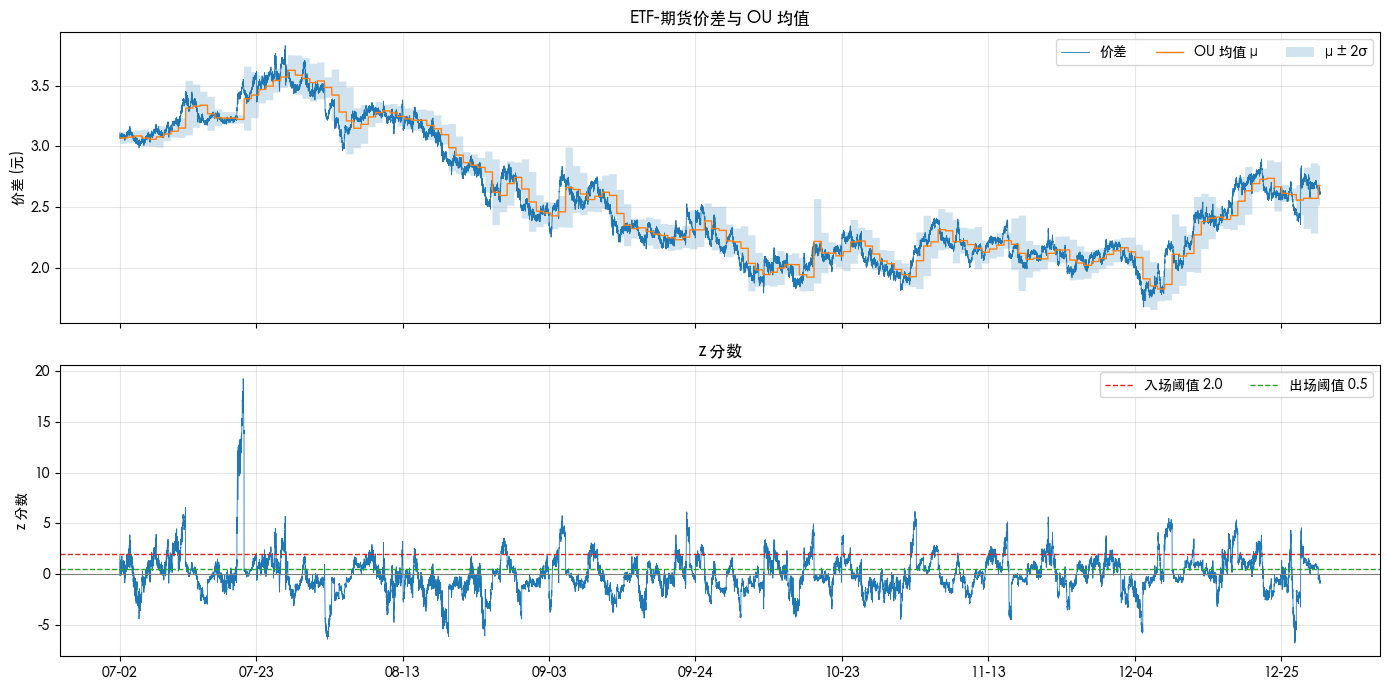

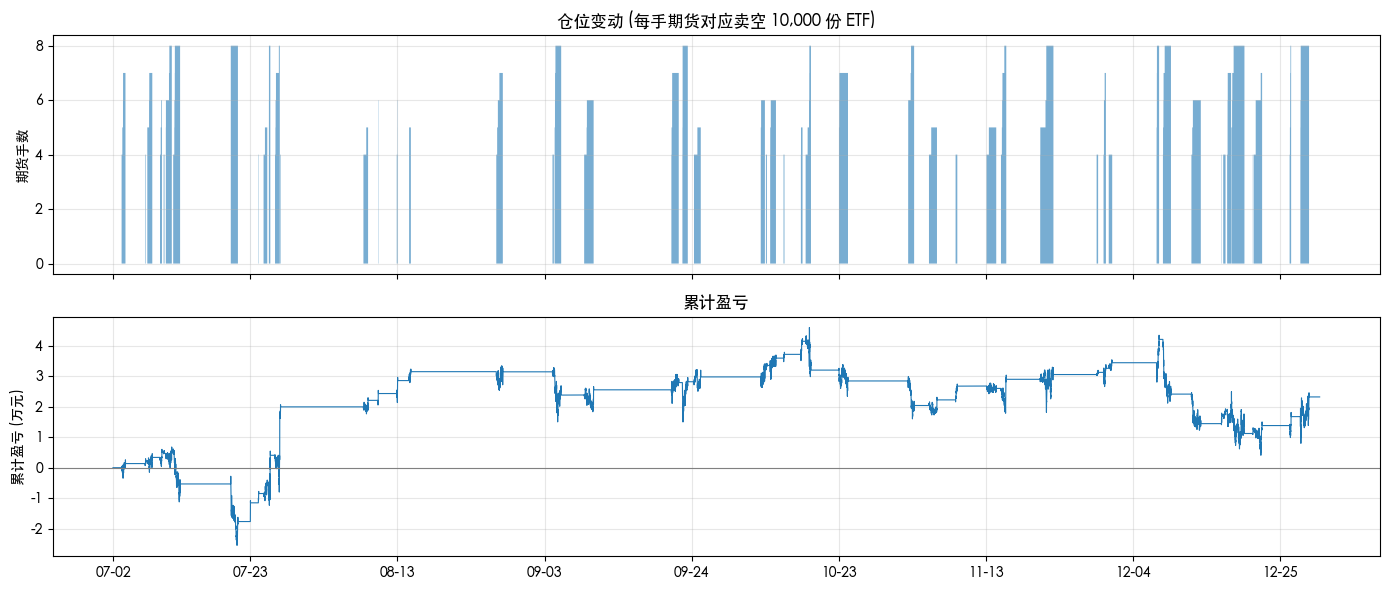

In [54]:
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif'] = ['PingFang SC', 'Heiti TC', 'Arial Unicode MS', 'SimHei', 'Noto Sans CJK SC', 'Noto Sans CJK JP']
plt.rcParams['axes.unicode_minus'] = False

OUT_2B = ROOT / 'task2b_output'
OUT_2B.mkdir(exist_ok=True)
ENTRY_Z, EXIT_Z = 2.0, 0.5

def date_ticks(ax, index, n=8):
    """横轴按 K 线序号排列(去掉夜间和周末的空白), 刻度显示日期"""
    days = pd.Series(np.arange(len(index)), index=index).groupby(index.normalize()).first()
    pick = days.iloc[::max(1, len(days) // n)]
    ax.set_xticks(pick.values)
    ax.set_xticklabels([d.strftime('%m-%d') for d in pick.index])

def plot_spread_z(log, fname='spread_zscore.png'):
    x = np.arange(len(log))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)
    ax1.plot(x, log['spread'], lw=0.6, label='价差')
    ax1.plot(x, log['mu'], lw=1.0, label='OU 均值 μ')
    ax1.fill_between(x, log['mu'] - 2 * log['sigma_eq'], log['mu'] + 2 * log['sigma_eq'],
                     alpha=0.2, label='μ ± 2σ')
    ax1.set_ylabel('价差 (元)')
    ax1.set_title('ETF-期货价差与 OU 均值')
    ax1.legend(loc='upper right', ncol=3)
    ax1.grid(alpha=0.3)
    ax2.plot(x, log['z'], lw=0.6)
    ax2.axhline(ENTRY_Z, color='tab:red', ls='--', lw=1, label=f'入场阈值 {ENTRY_Z}')
    ax2.axhline(EXIT_Z, color='tab:green', ls='--', lw=1, label=f'出场阈值 {EXIT_Z}')
    ax2.axhline(0, color='grey', lw=0.8)
    ax2.set_ylabel('z 分数')
    ax2.set_title('z 分数')
    ax2.legend(loc='upper right', ncol=2)
    ax2.grid(alpha=0.3)
    date_ticks(ax2, log.index)
    fig.tight_layout()
    fig.savefig(OUT_2B / fname, dpi=150)
    plt.show()

def plot_position_equity(log, capital, fname='position_equity.png'):
    x = np.arange(len(log))
    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 6), sharex=True)
    ax1.fill_between(x, 0, log['lots'], step='post', alpha=0.6)
    ax1.set_ylabel('期货手数')
    ax1.set_title('仓位变动 (每手期货对应卖空 10,000 份 ETF)')
    ax1.grid(alpha=0.3)
    ax2.plot(x, (log['equity'] - capital) / 1e4, lw=0.8)
    ax2.axhline(0, color='grey', lw=0.8)
    ax2.set_ylabel('累计盈亏 (万元)')
    ax2.set_title('累计盈亏')
    ax2.grid(alpha=0.3)
    date_ticks(ax2, log.index)
    fig.tight_layout()
    fig.savefig(OUT_2B / fname, dpi=150)
    plt.show()

plot_spread_z(log)
plot_position_equity(log, CAPITAL)

# 导出: 绩效指标、OU 参数(初始 + 每次重估)、交易记录
result.to_csv(OUT_2B / 'backtest_metrics.csv', header=['value'])
pd.Series(init_params).to_csv(OUT_2B / 'ou_initial_params.csv', header=['value'])
fits.to_csv(OUT_2B / 'ou_rolling_params.csv', index=False)
trades.to_csv(OUT_2B / 'trade_records.csv', index=False)

# Numba提速

为csv文件读取提速

In [55]:
from numba import njit

# ---------- 基础解析函数: 都在字节层面操作, 48 是字符 '0' 的编码 ----------

@njit
def _days_from_civil(y, m, d):
    """把一个日期转换成整数，表示它距离1970-01-01有多少天，这里只处理日期，没有处理时分秒和时区"""
    # trick1: 把“三月”当作一年的开始，这样子2月就是最后，2月之前的天数都是固定的
    if m <= 2:
        y -= 1
    # 400年一周期
    era = y // 400
    # yoe表示当前位于上一个周期的年份数
    yoe = y - era * 400
    # 将月份重新排列，3月是0，4月是1……
    mp = (m + 9) % 12
    # 计算日期距离“这一年的 3 月 1 日”有多少天
    # (153 * mp + 2) // 5 计算的是月份之前的天数， d - 1是计算月内的天数
    doy = (153 * mp + 2) // 5 + d - 1
    # yoe*365: 先假设之前所有年份都是 365 天
    # yoe // 4: 补上每四年出现的闰日
    # - yoe // 100: 扣掉整百年份中不应该算的闰日
    # doy: 再加上当前这一年已经过去的天数
    doe = yoe * 365 + yoe // 4 - yoe // 100 + doy
    # 由于我们算出来的doe的起点是0000-03-01，我们要把他折回1970-01-01，两者相差719468
    return era * 146097 + doe - 719468

@njit
def _parse_time(buf, a, b):
    # 从一段时间文本中读出年月日、时分秒和毫秒，再转换成“从 1970-01-01 00:00:00 起算的纳秒数”
    # buf是存储时间文本的字节数组，a是时间文本的起始位置，b是结束位置
    # 对于一个文本，2024-03-15 09:30:05.123
    """解析 'YYYY-MM-DD HH:MM:SS' 或 'YYYY-MM-DD HH:MM:SS.fff', 返回纳秒时间戳"""
    # 年份在buf[0:4]上，直接取，通过ASCII码把字符编码转成数字
    y = (buf[a] - 48) * 1000 + (buf[a + 1] - 48) * 100 + (buf[a + 2] - 48) * 10 + (buf[a + 3] - 48)
    # 月份在buf[5]和buf[6]的位置上，直接取这两个字节
    mo = (buf[a + 5] - 48) * 10 + (buf[a + 6] - 48)
    d = (buf[a + 8] - 48) * 10 + (buf[a + 9] - 48)
    # 小时
    h = (buf[a + 11] - 48) * 10 + (buf[a + 12] - 48)
    # 分钟
    mi = (buf[a + 14] - 48) * 10 + (buf[a + 15] - 48)
    # 秒
    se = (buf[a + 17] - 48) * 10 + (buf[a + 18] - 48)
    # 如果有毫秒
    ms = 0
    if b - a >= 23 and buf[a + 19] == 46:                  # 46 = '.', 有毫秒部分
        ms = (buf[a + 20] - 48) * 100 + (buf[a + 21] - 48) * 10 + (buf[a + 22] - 48)
    days = _days_from_civil(y, mo, d)
    # 把各部分统一换算成纳秒
    return ((days * 86400 + h * 3600 + mi * 60 + se) * 1000 + ms) * 1_000_000

@njit
def _parse_float(buf, a, b):
    """解析数字字符串(支持负号、小数、科学计数法); 空字段返回 NaN，ex. "-12.34e-2"→ -0.1234； "123"→ 123.0"""
    # buf是数字文本，a是起点，b是终点
    if a >= b:
        return np.nan
    i = a
    neg = False
    if buf[i] == 45:                                       # 45是'-'的ASCII编码
        neg = True
        i += 1
    mant = 0                                               # 把所有数字当作整数累加
    ndec = 0                                               # 小数位数
    seen_dot = False                                        # 是否已经遇到小数点
    # 
    while i < b:
        c = buf[i]
        if c == 46:                                        # 46是'.'的ASCII编码
            seen_dot = True
        elif c == 101 or c == 69:                          # 'e' 或 'E'，识别科学技术法，如果是科学技术法就另作处理
            break
        else:
            mant = mant * 10 + (c - 48)
            if seen_dot:
                ndec += 1
        i += 1
    exp = 0
    if i < b:                                              # 科学计数法的指数部分
        i += 1
        eneg = False
        if buf[i] == 45:
            eneg = True
            i += 1
        elif buf[i] == 43:
            i += 1
        # 把指数的数字拼起来
        while i < b:
            exp = exp * 10 + (buf[i] - 48)
            i += 1
        if eneg:
            exp = -exp
    # 整数除以 10 的幂, 结果与 pandas 解析的数值完全相同
    p = exp - ndec # 把“小数位数”和“指数”合并，确定到底小数点要移动几位
    val = mant * 10.0 ** p if p >= 0 else mant / 10.0 ** (-p)
    return -val if neg else val

@njit
def _count_lines(buf):
    # 统计字节数组 buf 里有多少个换行符 \n
    n = 0
    for i in range(buf.shape[0]):
        if buf[i] == 10:                                   # '\n'的ASCII编码是10
            n += 1
    return n

@njit
def _parse_csv(buf, n_rows, code_col, time_col, float_cols):
    # 它逐个字节读取 CSV，找出每个字段，然后把指定的时间列、数值列解析出来，同时记录代码列在原始数据中的位置

    # 提前准备存储结果的数组
    n_f = float_cols.shape[0]   # 需要解析的数值列数量
    floats = np.empty((n_rows, n_f), dtype=np.float64)
    times = np.empty(n_rows, dtype=np.int64)
    code_start = np.empty(n_rows, dtype=np.int64)
    code_len = np.empty(n_rows, dtype=np.int64)
    n = buf.shape[0]
    i = 0
    while i < n and buf[i] != 10:                          # 跳过表头
        i += 1
    i += 1
    row = 0 # 代表当前是第几行数据
    while i < n and row < n_rows:
        col = 0 # 当前是第几列
        start = i   # 当前字段从哪里开始
        while True:
            c = buf[i] if i < n else 10
            if c == 44 or c == 10 or c == 13:              # ',' 或换行(10代表换行，13代表回车): 一个字段结束
                if col == code_col:
                    code_start[row] = start
                    code_len[row] = i - start
                elif col == time_col:
                    times[row] = _parse_time(buf, start, i)
                else:
                    for k in range(n_f):
                        if float_cols[k] == col:
                            floats[row, k] = _parse_float(buf, start, i)
                if c != 44:                                # 如果分隔符不是逗号，而是换行，就结束这一行
                    break
                # 如果是逗号
                col += 1
                start = i + 1
            i += 1
        # 一行结束后
        while i < n and (buf[i] == 10 or buf[i] == 13):
            i += 1
        row += 1
    return times[:row], floats[:row], code_start[:row], code_len[:row]

@njit
def _code_ids(buf, code_start, code_len, max_codes=256):
    """把每行的合约代码转成编号; 只保存每种代码第一次出现的位置, 避免创建几百万个字符串"""
    n = code_start.shape[0]
    ids = np.empty(n, dtype=np.int64)
    u_start = np.empty(max_codes, dtype=np.int64)
    u_len = np.empty(max_codes, dtype=np.int64)
    n_u = 0
    last = -1
    for r in range(n):
        a, l = code_start[r], code_len[r]
        # 快速路径: 和上一行的代码相同(数据按合约连续排列, 绝大多数行走这里)
        if last >= 0 and l == u_len[last]:
            same = True
            for k in range(l):
                if buf[a + k] != buf[u_start[last] + k]:
                    same = False
                    break
            if same:
                ids[r] = last
                continue
        # 否则在已出现过的代码里查找, 找不到就登记为新代码
        found = -1
        for j in range(n_u):
            if l == u_len[j]:
                same = True
                for k in range(l):
                    if buf[a + k] != buf[u_start[j] + k]:
                        same = False
                        break
                if same:
                    found = j
                    break
        if found < 0:
            u_start[n_u] = a
            u_len[n_u] = l
            found = n_u
            n_u += 1
        ids[r] = found
        last = found
    return ids, u_start[:n_u], u_len[:n_u]

def read_csv_numba(path, code_col, time_col, float_cols):
    """用 numba 解析 CSV, 返回与 pd.read_csv 相同格式的 DataFrame"""
    buf = np.fromfile(path, dtype=np.uint8)                # 整个文件按字节读入
    n_rows = _count_lines(buf)
    times, floats, cs, cl = _parse_csv(buf, n_rows, code_col, time_col,
                                       np.array(list(float_cols.values()), dtype=np.int64))
    ids, us, ul = _code_ids(buf, cs, cl)
    names = [bytes(buf[a:a + l]).decode('ascii') for a, l in zip(us, ul)]
    df = pd.DataFrame(floats, columns=list(float_cols))
    df.insert(0, 'trade_time', times.view('datetime64[ns]'))
    df.insert(0, 'code', np.array(names, dtype=object)[ids])
    return df

In [56]:
# 期货文件中需要的列及其位置(从 0 开始数): 代码第 1 列, 时间第 2 列
FUT_FLOAT_COLS = {'last': 4, 'pre_settle': 5, 'pre_close': 6,
                  'volume': 11, 'ask_price1': 18, 'bid_price1': 20}

def load_futures_numba():
    """与 load_futures 相同的清洗步骤, 只是读取和时间解析改用 numba"""
    df = read_csv_numba(FUT_FILE, code_col=1, time_col=2, float_cols=FUT_FLOAT_COLS)
    n0 = len(df)
    df = df.dropna(subset=['trade_time'])
    end_excl = pd.Timestamp(END) + pd.Timedelta(days=1)
    df = df[(df['trade_time'] >= START) & (df['trade_time'] < end_excl)]
    df = df.sort_values('trade_time').drop_duplicates('trade_time', keep='last')
    t = df['trade_time'].dt.time
    am = (t >= pd.Timestamp('09:30').time()) & (t <= pd.Timestamp('11:30').time())
    pm = (t >= pd.Timestamp('13:00').time()) & (t <= pd.Timestamp('15:15').time())
    df = df[am | pm]
    df = df[(df['last'] > 0) & (df['bid_price1'] > 0) & (df['ask_price1'] > 0)]
    df = df[(df['last'] / df['pre_settle'] - 1).abs() <= 0.035]
    print(f'期货(numba): 原始 {n0:,} 行 -> 清洗后 {len(df):,} 行, '
          f'{df["trade_time"].dt.date.nunique()} 个交易日')
    return df.reset_index(drop=True)

import time

# numba 第一次调用时要编译, 先用一个很小的文件预热, 避免把编译时间算进对比
_tiny = ROOT / 'task2b_output' / '_numba_warmup.csv'
_tiny.write_text('h\nTL,2025-07-01 09:29:00.300,x,x,1.5,2,3,x,x,x,x,4,x,x,x,x,x,x,5,x,6\n')
read_csv_numba(_tiny, 1, 2, FUT_FLOAT_COLS)
_tiny.unlink()

timing = []
for rep in range(3):
    t0 = time.perf_counter()
    fut_pd = load_futures()               # 原方法
    t1 = time.perf_counter()
    fut_nb = load_futures_numba()         # numba 方法
    t2 = time.perf_counter()
    timing.append({'第几次': rep + 1, 'pandas(秒)': t1 - t0, 'numba(秒)': t2 - t1})

timing = pd.DataFrame(timing).set_index('第几次')
timing['加速倍数'] = timing['pandas(秒)'] / timing['numba(秒)']
print('两种方法结果完全一致:', fut_pd.equals(fut_nb))
timing.round(2)

期货: 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
期货(numba): 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
期货: 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
期货(numba): 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
期货: 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
期货(numba): 原始 3,427,094 行 -> 清洗后 3,426,465 行, 125 个交易日
两种方法结果完全一致: True


,pandas(秒),numba(秒),加速倍数
第几次,,,
1,7.37,4.97,1.48
2,6.79,5.02,1.35
3,6.80,4.63,1.47


为backtraker加速

In [57]:
def build_ticks(pair):
    """
    整理 3 秒行情, 供止损检查使用:
      - 用买一卖一的中间价, 不受成交价在买卖价之间来回跳的影响;
      - 中间价同样做复权(加上复权价与成交价之差), 和策略使用的价格保持一致;
      - 买一或卖一缺失时, 退回使用复权后的成交价;
      - bar_time: 这条行情属于哪一根 1 分钟 K 线(与 to_minute_bars 的规则相同, 向上取整到分钟)
    """
    ok_e = (pair['bid_price1'] > 0) & (pair['ask_price1'] > 0)
    ok_f = (pair['fut_bid'] > 0) & (pair['fut_ask'] > 0)
    etf_mid = (pair['bid_price1'] + pair['ask_price1']) / 2 + (pair['etf_adj'] - pair['last'])
    fut_mid = (pair['fut_bid'] + pair['fut_ask']) / 2 + (pair['fut_adj'] - pair['fut_last'])
    bar_time = pair['trade_time'].dt.ceil('min')
    return {
        'bar_time': bar_time.values.astype('datetime64[ns]').view(np.int64),
        'time': pair['trade_time'].values,
        'etf_mid': np.where(ok_e, etf_mid, pair['etf_adj']).astype(np.float64),
        'fut_mid': np.where(ok_f, fut_mid, pair['fut_adj']).astype(np.float64),
    }

TICKS = build_ticks(pair)
print(f"3 秒行情 {len(TICKS['time']):,} 条; 中间价缺失而退回成交价的比例: "
      f"ETF {(~((pair['bid_price1'] > 0) & (pair['ask_price1'] > 0))).mean():.2%}, "
      f"期货 {(~((pair['fut_bid'] > 0) & (pair['fut_ask'] > 0))).mean():.2%}")

3 秒行情 600,012 条; 中间价缺失而退回成交价的比例: ETF 0.00%, 期货 0.00%


In [58]:
from numba import njit

@njit
def _ou_fit(x, sd):
    """与 estimate_ou 完全相同的计算; 返回 (是否有效, theta, mu, sigma, sigma_eq, half_life, a, n)"""
    m = x.shape[0]      # 观测值数量
    n = 0   # 可用于拟合的相邻数据对数量
    for k in range(m - 1):                 # 只保留同一天内相邻的数据对
        if sd[k + 1]:
            n += 1
    if n < 30:      # 少于30对，数据不足
        return False, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, n
    # 把相邻数据整理成回归的输入和目标
    x0 = np.empty(n)
    x1 = np.empty(n)
    j = 0
    for k in range(m - 1):
        if sd[k + 1]:
            x0[j] = x[k]
            x1[j] = x[k + 1]
            j += 1
    mx = x0.mean()
    my = x1.mean()
    sxx = ((x0 - mx) ** 2).sum()
    if sxx <= 0:
        return False, np.nan, np.nan, np.nan, np.nan, np.nan, np.nan, n
    # 最小二乘法
    a = ((x0 - mx) * (x1 - my)).sum() / sxx # 斜率
    b = my - a * mx # 截距
    # 检查是否符合标准 OU 均值回归，如果a>=1，说明偏离不会回归
    if not (0 < a < 1):
        return False, np.nan, np.nan, np.nan, np.nan, np.nan, a, n
    resid = x1 - a * x0 - b
    var_e = (resid ** 2).sum() / (n - 2)
    # 把回归结果换算成 OU 参数
    theta = -np.log(a)      # 均值回归速度theta=lna，
    # 长期回归的中心水平
    mu = b / (1 - a)
    sigma_eq = np.sqrt(var_e / (1 - a ** 2))    #  长期围绕 mu 波动的标准差
    sigma = sigma_eq * np.sqrt(2 * theta)   # OU 方程中的随机噪声强度
    return True, theta, mu, sigma, sigma_eq, np.log(2) / theta, a, n    # np.log(2) / theta是在计算半衰期

@njit
def _backtest_core(spread, same_day, etf_raw, etf_adj, fut_adj, roll, times,
                   t_start, t_end, window, refit_every, entry_z, exit_z, full_z,
                   max_lots, max_capital, capital,
                   etf_per_lot, fut_mult, etf_fee, fut_fee, etf_slip, fut_slip,
                   tick_start, tick_end, tk_etf, tk_fut, stop_trade, stop_day):
    """
    按时间顺序，一根 K 线一根 K 线地往后走，模拟持仓、盈亏、手续费、换月和交易决策，最后返回资金和交易记录
    整个流程为：
    读取一根 K 线 -> 计算已有持仓的盈亏，扣除之前订单的费用 -> 检查是否允许交易、是否需要换月 -> 定期用最近的数据重新估计 OU 参数 
    -> 计算当前价差的 Z-score -> 决定开仓、加仓、平仓，或者保持不动 -> 进入下一根 K 线
    """
    """
    spread: 用来拟合 OU、计算交易信号的价差序列
    same_day: 标记相邻数据是否属于同一天，供 _ou_fit 使用
    etf_raw: ETF 原始价格，用于估算资金能支持多少手
    etf_adj、fut_adj: 代码用于计算持仓盈亏的价格序列
    roll: 哪根 K 线发生期货换月
    times: 每根 K 线的时间
    t_start、t_end: 策略允许交易的时间范围
    window、refit_every: OU 拟合窗口长度、重新拟合的间隔
    entry_z、exit_z、full_z: 开仓阈值、平仓阈值和仓位放大尺度
    max_lots、max_capital: 最大手数、用于限制仓位的资金金额
    capital: 初始资金
    etf_per_lot、fut_mult: 每手对应的 ETF 数量、期货合约乘数
    *_fee、*_slip	手续费和滑点参数
    tick_start、tick_end: 每根 K 线对应的 3 秒行情在 tk_etf / tk_fut 中的起止位置
    tk_etf、tk_fut: 3 秒行情的复权中间价, 用于止损检查
    stop_trade、stop_day: 单笔止损金额、每日止损金额(元), 小于等于 0 表示不启用
    """
    
    n = spread.shape[0]
    # 保存结果的数组,保存策略运行过程中的K线位置、OU 均值、长期标准差、Z-score、持仓手数、账户权益
    log_idx = np.empty(n, np.int64); log_mu = np.empty(n); log_sig = np.empty(n)
    log_z = np.empty(n); log_lots = np.empty(n, np.int64); log_eq = np.empty(n)
    n_log = 0
    # 交易记录
    tr_idx = np.empty(3 * n + 3, np.int64);     # 交易时间
    tr_kind = np.empty(3 * n + 3, np.int64)     # 交易类型，0 开仓, 1 加仓, 2 平仓, 3 期末平仓, 4 换月, 5 单笔止损, 6 每日止损
    tr_from = np.empty(3 * n + 3, np.int64);    # 原持仓
    tr_to = np.empty(3 * n + 3, np.int64)       # 新持仓
    tr_z = np.empty(3 * n + 3);     # 当时的Z-score
    tr_slip = np.empty(3 * n + 3)       # 滑点金额
    tr_tick = np.full(3 * n + 3, -1, np.int64)   # 止损发生在哪一条 3 秒行情(-1 表示不是止损)
    n_tr = 0
    # 保存每次 OU 参数拟合的时间、结果和是否有效
    fit_idx = np.empty(n, np.int64); fit_val = np.empty((n, 7)); fit_ok = np.empty(n, np.bool_)
    n_fit = 0

    # 初始化账户和策略状态
    equity = capital
    lots = 0                 # 当前持仓(期货手数), 下单后立即更新
    pending_cost = 0.0       # 本根下单产生、下一根成交时才扣除的费用
    mu = np.nan             # OU参数尚未估计
    sig_eq = np.nan         
    since_fit = -1           # -1 表示还没估计过
    # 止损相关的状态
    use_stop = stop_trade > 0 or stop_day > 0
    trade_start_eq = capital # 当前回合开仓时的资金, 用于计算单笔(回合)亏损
    day_start_eq = capital   # 上一交易日收盘时的资金, 用于计算当日亏损
    wait_reset = False       # 单笔止损后, 要等 z 回落到出场阈值以下才允许再开仓
    day_blocked = False      # 触发每日止损后, 当天不再开仓

    for i in range(n):
        # ---- 0) 新的一天: 记录日初资金(即上一交易日收盘时的资金), 解除每日止损的禁令 ----
        if not same_day[i]:
            day_start_eq = equity - pending_cost
            day_blocked = False

        # ---- 0.5) 止损检查: 在这一分钟内逐条检查 3 秒行情, 用复权中间价计算浮亏 ----
        stopped = False
        if use_stop and i > 0 and lots > 0:
            base = equity - pending_cost          # 上一根收盘时的资金(上一根下单的费用也算进去)
            for k in range(tick_start[i], tick_end[i]):
                eq_t = base + lots * (-etf_per_lot * (tk_etf[k] - etf_adj[i - 1])
                                      + fut_mult * (tk_fut[k] - fut_adj[i - 1]))
                hit = 0
                if stop_trade > 0 and eq_t - trade_start_eq < -stop_trade:
                    hit = 5                       # 本回合亏损超过单笔止损
                elif stop_day > 0 and eq_t - day_start_eq < -stop_day:
                    hit = 6                       # 当日亏损超过每日止损
                if hit > 0:
                    # 按这一刻的中间价立即全部平仓, 并扣除滑点和手续费
                    slip = lots * (etf_per_lot * etf_slip + fut_mult * fut_slip)
                    fee = lots * (etf_per_lot * tk_etf[k] * etf_fee + fut_fee)
                    equity = eq_t - slip - fee
                    pending_cost = 0.0
                    tr_idx[n_tr] = i; tr_kind[n_tr] = hit; tr_from[n_tr] = lots; tr_to[n_tr] = 0
                    tr_z[n_tr] = np.nan; tr_slip[n_tr] = slip; tr_tick[n_tr] = k; n_tr += 1
                    lots = 0
                    if hit == 5:
                        wait_reset = True
                    else:
                        day_blocked = True
                    stopped = True
                    break

        if not stopped:
            # 每来一根 K 线，先计算已有持仓的盈亏
            # (订单按下单那根的收盘价成交, 所以新持仓从下单那根的收盘价开始计算盈亏)
            if i > 0 and lots != 0:
                equity += lots * (-etf_per_lot * (etf_adj[i] - etf_adj[i - 1])     # ETF 空头
                                  + fut_mult * (fut_adj[i] - fut_adj[i - 1]))      # 期货多头
            # ---- 2) 上一根下的单在这一根成交: 扣除手续费、滑点等费用 ----
            equity -= pending_cost
            pending_cost = 0.0

        # ---- 3) 以下与 OUPairStrategy.next 一一对应 ----
        if i + 1 < window:                                   # 数据不足一个完整窗口时，先预热，不拟合、不交易
            continue
        if t_start >= 0 and times[i] < t_start:         # 还没到开始时间，也不执行策略
            continue
        if t_end >= 0 and times[i] > t_end:                  # 超过结束时间: 平仓后不再交易
            if lots > 0:
                d = lots
                slip = d * (etf_per_lot * etf_slip + fut_mult * fut_slip)
                fee = d * (etf_per_lot * etf_adj[i] * etf_fee + fut_fee)
                pending_cost += slip + fee
                tr_idx[n_tr] = i; tr_kind[n_tr] = 3; tr_from[n_tr] = lots; tr_to[n_tr] = 0
                tr_z[n_tr] = np.nan; tr_slip[n_tr] = slip; n_tr += 1
                lots = 0
            continue

        if roll[i] and lots > 0:                             # 如果发生换月，计入换月费用，即平掉旧合约 + 开出新合约
            rc = lots * (2 * fut_fee + 2 * fut_mult * fut_slip)
            pending_cost += rc
            tr_idx[n_tr] = i; tr_kind[n_tr] = 4; tr_from[n_tr] = lots; tr_to[n_tr] = lots
            tr_z[n_tr] = np.nan; tr_slip[n_tr] = rc; n_tr += 1

        if since_fit < 0 or since_fit >= refit_every:        # 如果还没拟合过或者距离上一次拟合已经达到指定间隔，就重估 OU 参数
            m = min(window, i + 1)  # 使用最近 window 根的数据
            ok, th, mu_, sg, se, hl, a, nn = _ou_fit(spread[i - m + 1:i + 1],
                                                      same_day[i - m + 1:i + 1])
            if ok:                                           # 无效时沿用上一次的参数
                mu = mu_
                sig_eq = se
            # 记录你和结果
            fit_idx[n_fit] = i; fit_ok[n_fit] = ok
            fit_val[n_fit, 0] = th; fit_val[n_fit, 1] = mu_; fit_val[n_fit, 2] = sg
            fit_val[n_fit, 3] = se; fit_val[n_fit, 4] = hl; fit_val[n_fit, 5] = a
            fit_val[n_fit, 6] = nn
            n_fit += 1
            since_fit = 0
        since_fit += 1

        # 计算z-score
        z = (spread[i] - mu) / sig_eq
        log_idx[n_log] = i; log_mu[n_log] = mu; log_sig[n_log] = sig_eq
        log_z[n_log] = z; log_lots[n_log] = lots; log_eq[n_log] = equity
        n_log += 1

        if i >= n - 2:                                       # 最后两根不再下单
            continue

        # 单笔止损后, z 已回落到出场阈值以下, 说明这一轮偏离结束, 允许下一次开仓
        if wait_reset and z < exit_z:
            wait_reset = False

        target = lots
        kind = 0
        if lots > 0 and z < exit_z:
            # 如果已有持仓，并且价差已经回落到平仓阈值以下
            target = 0
            kind = 2
        elif z > entry_z and not wait_reset and not day_blocked:
            # 如果价差超过开仓阈值
            cap_lots = int(max_capital // (etf_per_lot * etf_raw[i]))
            want = int(max_lots * z / full_z)
            t = max(1, min(max_lots, cap_lots, want))
            if t > lots:
                target = t
                kind = 0 if lots == 0 else 1
        # 如果仓位发生变化
        if target != lots:
            if lots == 0:
                trade_start_eq = equity     # 新回合开始, 记下开仓时的资金
            d = abs(target - lots)      # d是这次需要交易的手数
            slip = d * (etf_per_lot * etf_slip + fut_mult * fut_slip)
            fee = d * (etf_per_lot * etf_adj[i] * etf_fee + fut_fee)   # ETF 按成交金额, 期货按手
            pending_cost += slip + fee
            tr_idx[n_tr] = i; tr_kind[n_tr] = kind; tr_from[n_tr] = lots; tr_to[n_tr] = target
            tr_z[n_tr] = z; tr_slip[n_tr] = slip; n_tr += 1
            lots = target

    return (log_idx[:n_log], log_mu[:n_log], log_sig[:n_log], log_z[:n_log],
            log_lots[:n_log], log_eq[:n_log],
            tr_idx[:n_tr], tr_kind[:n_tr], tr_from[:n_tr], tr_to[:n_tr], tr_z[:n_tr], tr_slip[:n_tr], tr_tick[:n_tr],
            fit_idx[:n_fit], fit_val[:n_fit], fit_ok[:n_fit], equity)

In [59]:
ACTIONS = np.array(['开仓', '加仓', '平仓', '期末平仓', '换月', '单笔止损', '每日止损'], dtype=object)

def run_pair_backtest_numba(bars, trade_start=None, trade_end=None, window=480, refit_every=180,
                            entry_z=2.0, exit_z=0.5, full_z=4.0, max_lots=8, max_capital=10_000_000,
                            stop_loss_trade=None, stop_loss_day=None):
    """numba 版回测: 参数和返回值(log, trades, fits)与 run_pair_backtest 完全相同
    额外参数: stop_loss_trade 单笔(回合)止损金额, stop_loss_day 每日止损金额, 单位元, None 表示不启用;
             止损用 3 秒行情的复权中间价检查(需要先运行构建 TICKS 的 cell)"""
    times = bars.index.values.astype('datetime64[ns]').view(np.int64)       # 把时间索引转换成纳秒整数
    to_ns = lambda t: -1 if t is None else pd.Timestamp(t).value
    roll = (bars['fut_code'] != bars['fut_code'].shift()).values        # 根据合约代码变化，标记换月
    roll[0] = False # 第一行没有上一行，不能把它算作换月，因此手动设为 False

    # 止损: 找出每根 1 分钟 K 线对应的 3 秒行情的起止位置
    use_stop = stop_loss_trade is not None or stop_loss_day is not None
    if use_stop:
        tick_start = np.searchsorted(TICKS['bar_time'], times, side='left')
        tick_end = np.searchsorted(TICKS['bar_time'], times, side='right')
        tk_etf, tk_fut = TICKS['etf_mid'], TICKS['fut_mid']
    else:
        tick_start = tick_end = np.zeros(len(bars), dtype=np.int64)
        tk_etf = tk_fut = np.zeros(1)

    out = _backtest_core(
        bars['spread'].values.astype(np.float64), bars['same_day'].values.astype(np.bool_),
        bars['etf_last'].values.astype(np.float64), bars['etf_adj'].values.astype(np.float64),
        bars['fut_adj'].values.astype(np.float64), roll, times,
        to_ns(trade_start), to_ns(trade_end), int(window), int(refit_every),
        float(entry_z), float(exit_z), float(full_z), int(max_lots),
        float(max_capital), float(max_capital),
        # 成本参数每次调用时读取, 所以 cost_scale 对它同样有效
        float(ETF_PER_LOT), float(FUT_MULT), float(ETF_FEE), float(FUT_FEE),
        float(ETF_SLIP), float(FUT_SLIP),
        tick_start.astype(np.int64), tick_end.astype(np.int64), tk_etf, tk_fut,
        float(stop_loss_trade or 0), float(stop_loss_day or 0))
    (li, lmu, lsig, lz, llots, leq, ti, tk, tf, tt, tz, ts, tick, fi, fv, fok, final_eq) = out

    log = pd.DataFrame({'spread': bars['spread'].values[li], 'mu': lmu, 'sigma_eq': lsig,
                        'z': lz, 'lots': llots, 'equity': leq}, index=bars.index[li])
    log.index.name = 'time'
    log.loc[log.index[-1], 'equity'] = final_eq            # 与 backtrader 版一致: 最后一行用期末资金
    trades = pd.DataFrame({'time': bars.index[ti], 'action': ACTIONS[tk],
                           'lots_from': tf, 'lots_to': tt, 'z': tz,
                           'spread': bars['spread'].values[ti], 'etf': bars['etf_last'].values[ti],
                           'slippage': ts})
    # 止损发生在分钟内部: 用那一条 3 秒行情的时间和价差
    is_stop = tick >= 0
    if is_stop.any():
        trades.loc[is_stop, 'time'] = TICKS['time'][tick[is_stop]]
        trades.loc[is_stop, 'spread'] = (TICKS['etf_mid'] - TICKS['fut_mid'])[tick[is_stop]]
    fits = pd.DataFrame(fv, columns=['theta', 'mu', 'sigma', 'sigma_eq', 'half_life', 'a', 'n'])
    fits['time'] = bars.index[fi]
    fits['valid'] = fok
    return log, trades, fits

In [60]:
import time

# 预热: 第一次调用要编译
run_pair_backtest_numba(bars.iloc[:3000])

# 对账用的前半段数据和起始时间(与任务 3 中的 train_bars / TRAIN_START 定义相同)
_train_bars = bars[bars['date'] < split_date]
_train_start = bars.index[2400]

test_cases = {
    '默认参数, 全程':     (bars, None, None, dict()),
    '夏普最优, 全程':     (bars, None, None, dict(window=300, entry_z=3.8, exit_z=-0.4)),
    '短窗口高频':         (bars, None, None, dict(window=180, entry_z=1.5, exit_z=1.0, refit_every=60)),
    '前半段':             (_train_bars, _train_start, None, dict(window=300, entry_z=2.1, exit_z=-0.4)),
    '后半段':             (bars, split_date, None, dict(window=300, entry_z=3.1, exit_z=-0.4)),
}

rows = []
for name, (data, start, end, kw) in test_cases.items():
    t0 = time.perf_counter()
    log_bt, tr_bt, _ = run_pair_backtest(data, start, end, **kw)
    t1 = time.perf_counter()
    log_nb, tr_nb, _ = run_pair_backtest_numba(data, start, end, **kw)
    t2 = time.perf_counter()

    cols = ['time', 'action', 'lots_from', 'lots_to']
    same_trades = tr_bt[cols].reset_index(drop=True).equals(tr_nb[cols].reset_index(drop=True))
    rows.append({
        '情形': name,
        'backtrader(秒)': t1 - t0,
        'numba(毫秒)': (t2 - t1) * 1000,
        '加速倍数': (t1 - t0) / (t2 - t1),
        '交易完全相同': same_trades,
        '资金最大差异(元)': (log_bt['equity'] - log_nb['equity']).abs().max(),
        'backtrader收益': log_bt['equity'].iloc[-1] - CAPITAL,
        'numba收益': log_nb['equity'].iloc[-1] - CAPITAL,
    })

pd.DataFrame(rows).set_index('情形').round(4)

,backtrader(秒),numba(毫秒),加速倍数,交易完全相同,资金最大差异(元),backtrader收益,numba收益
情形,,,,,,,
"默认参数, 全程",4.5493,3.7219,1222.2984,True,0.0,23173.1365,23173.1365
"夏普最优, 全程",4.5020,3.2625,1379.9545,True,0.0,96810.2970,96810.2970
短窗口高频,4.8799,3.4815,1401.6833,True,0.0,-228713.2065,-228713.2065
前半段,2.1970,1.9496,1126.8888,True,0.0,79957.6000,79957.6000
后半段,4.4344,2.7635,1604.5974,True,0.0,29689.7345,29689.7345


# 参数优化： 入场阈值、出场阈值、滚动窗口长度

In [61]:
import optuna
# 让 Optuna 只显示“警告及以上级别”的日志，减少调参时的刷屏
optuna.logging.set_verbosity(optuna.logging.WARNING)

MAX_WINDOW=2400
TRAIN_START=bars.index[MAX_WINDOW]  
train_bars = bars[bars['date'] < split_date]        # 前半段: 用于搜索
MIN_OPENS = 10                                      # 开仓次数下限
N_TRIALS = 50

USE_NUMBA = True     # True: 用 numba 版回测(快); False: 用 backtrader 版(原方法)


def evaluate(data, trade_start=None, trade_end=None, **kw):
    """跑一次回测并返回绩效指标; 一笔交易都没有时返回 None"""
    runner = run_pair_backtest_numba if USE_NUMBA else run_pair_backtest
    log, trades, fits = runner(data, trade_start, trade_end, **kw)
    if len(trades) == 0:
        return None
    return pair_metrics(log, trades, CAPITAL)

def make_objective(metric, penalty, exit_low=-0.5):
    """生成目标函数: metric 是要最大化的指标, penalty 是无效参数的惩罚分, exit_low 是出场阈值的搜索下限"""
    def objective(trial):
        window = trial.suggest_int('window', 120, MAX_WINDOW, step=60)
        entry_z = trial.suggest_float('entry_z', 1.0, 4.0, step=0.1)
        exit_z = trial.suggest_float('exit_z', exit_low, 1.5, step=0.1)
        if exit_z > entry_z - 0.3:                  # 出场线必须明显低于入场线
            return penalty
        m = evaluate(train_bars, TRAIN_START, None,
                     window=window, entry_z=entry_z, exit_z=exit_z)
        if m is None or m['开仓次数'] < MIN_OPENS:   # 交易太少, 结果不可信
            return penalty
        # 把其他指标也记下来, 方便之后分析
        for k in ('绝对收益(元)', '夏普比率', '最大回撤', '开仓次数'):
            trial.set_user_attr(k, float(m[k]))
        return float(m[metric])
    return objective

def run_study(metric, penalty, seed=42, n_trials=N_TRIALS, exit_low=-0.5):
    study = optuna.create_study(direction='maximize',
                                sampler=optuna.samplers.TPESampler(seed=seed))
    study.optimize(make_objective(metric, penalty, exit_low), n_trials=n_trials,
                   show_progress_bar=True)
    return study

study_ret = run_study('绝对收益(元)', penalty=-1e6)      # 目标: 绝对收益
study_sharpe = run_study('夏普比率', penalty=-10.0)      # 目标: 夏普比率

print('收益最优:', study_ret.best_params, f'{study_ret.best_value:,.0f} 元')
print('夏普最优:', study_sharpe.best_params, f'{study_sharpe.best_value:.2f}')

# 每个目标下排名前 8 的试验
cols = ['number', 'value', 'params_window', 'params_entry_z', 'params_exit_z',
        'user_attrs_绝对收益(元)', 'user_attrs_夏普比率', 'user_attrs_开仓次数']
display(study_ret.trials_dataframe().sort_values('value', ascending=False)[cols].head(8).round(3))
display(study_sharpe.trials_dataframe().sort_values('value', ascending=False)[cols].head(8).round(3))

param_sets = {
    '默认参数': dict(window=480, entry_z=2.0, exit_z=0.5),
    '收益最优': study_ret.best_params,
    '夏普最优': study_sharpe.best_params,
}

rows = []
for name, p in param_sets.items():
    m_train = evaluate(train_bars, TRAIN_START, None, **p)     # 前半段(搜索用过)
    m_test = evaluate(bars, split_date, None, **p)             # 后半段(从未见过)
    row = {'参数组': name, **p}
    for tag, m in (('前半', m_train), ('后半', m_test)):
        for k in ('绝对收益(元)', '夏普比率', '最大回撤', '开仓次数'):
            row[f'{tag}_{k}'] = m[k]
    rows.append(row)

validation = pd.DataFrame(rows).set_index('参数组')
validation.to_csv(OUT_2B / 'optuna_validation.csv')
validation.round(4).T

  0%|          | 0/50 [00:00<?, ?it/s]

  0%|          | 0/50 [00:00<?, ?it/s]

收益最优: {'window': 300, 'entry_z': 2.2, 'exit_z': -0.4} 82,318 元
夏普最优: {'window': 360, 'entry_z': 3.2, 'exit_z': -0.4} 5.51


,number,value,params_window,params_entry_z,params_exit_z,user_attrs_绝对收益(元),user_attrs_夏普比率,user_attrs_开仓次数
31,31,82317.582,300,2.2,-0.4,82317.582,5.782,28.0
19,19,74782.026,300,3.1,-0.5,74782.026,5.953,15.0
35,35,63719.491,240,2.1,-0.3,63719.491,3.909,29.0
34,34,63719.491,240,2.1,-0.3,63719.491,3.909,29.0
26,26,63368.943,300,2.6,-0.3,63368.943,4.552,19.0
18,18,62500.267,360,2.4,-0.5,62500.267,3.775,19.0
41,41,61808.819,240,2.2,-0.3,61808.819,3.849,28.0
44,44,61263.806,300,2.5,0.0,61263.806,3.951,23.0


,number,value,params_window,params_entry_z,params_exit_z,user_attrs_绝对收益(元),user_attrs_夏普比率,user_attrs_开仓次数
26,26,5.506,360,3.2,-0.4,62753.082,5.506,12.0
41,41,5.503,300,3.7,-0.4,68946.924,5.503,12.0
31,31,5.331,300,3.6,-0.4,67126.035,5.331,12.0
32,32,5.047,300,3.8,-0.3,63706.056,5.047,11.0
29,29,5.036,300,3.6,-0.3,62965.267,5.036,12.0
46,46,4.499,360,2.9,-0.2,52361.763,4.499,13.0
25,25,4.432,360,2.5,-0.4,52886.639,4.432,16.0
35,35,4.351,300,3.6,0.0,58615.219,4.351,12.0


参数组,默认参数,收益最优,夏普最优
window,480.0000,300.0000,360.0000
entry_z,2.0000,2.2000,3.2000
exit_z,0.5000,-0.4000,-0.4000
前半_绝对收益(元),30189.7100,82317.5820,62753.0820
前半_夏普比率,2.7263,5.7821,5.5055
前半_最大回撤,-0.0023,-0.0025,-0.0023
前半_开仓次数,17.0000,28.0000,12.0000
后半_绝对收益(元),5908.3065,5142.8480,24374.3865
后半_夏普比率,0.3719,0.2432,1.1900
后半_最大回撤,-0.0032,-0.0043,-0.0033


## 扩大搜索(numba 版)

每个目标 500 次试验, 并把出场阈值的搜索下限从 -0.5 放宽到 -2.0(原来的最优值贴在边界上)。

In [62]:
import time

N_BIG = 500          # 每个目标的试验次数
EXIT_LOW = -2.0      # 放宽出场阈值的下限(原来是 -0.5, 最优值贴在边界上)

t0 = time.perf_counter()
study_ret_big = run_study('绝对收益(元)', penalty=-1e6, n_trials=N_BIG, exit_low=EXIT_LOW)
study_sharpe_big = run_study('夏普比率', penalty=-10.0, n_trials=N_BIG, exit_low=EXIT_LOW)
print(f'两次搜索共 {2 * N_BIG} 次回测, 用时 {time.perf_counter() - t0:.1f} 秒')
print('收益最优(500次):', study_ret_big.best_params, f'{study_ret_big.best_value:,.0f} 元')
print('夏普最优(500次):', study_sharpe_big.best_params, f'{study_sharpe_big.best_value:.2f}')

# 和原来 50 次的结果放在一起, 前半段 / 后半段对比
param_sets_big = {
    '默认参数':          dict(window=480, entry_z=2.0, exit_z=0.5),
    '收益最优(50次)':    study_ret.best_params,
    '夏普最优(50次)':    study_sharpe.best_params,
    '收益最优(500次)':   study_ret_big.best_params,
    '夏普最优(500次)':   study_sharpe_big.best_params,
}

rows = []
for name, p in param_sets_big.items():
    m_train = evaluate(train_bars, TRAIN_START, None, **p)     # 前半段(搜索用过)
    m_test = evaluate(bars, split_date, None, **p)             # 后半段(从未见过)
    row = {'参数组': name, **p}
    for tag, m in (('前半', m_train), ('后半', m_test)):
        for k in ('绝对收益(元)', '夏普比率', '最大回撤', '开仓次数'):
            row[f'{tag}_{k}'] = m[k]
    rows.append(row)

validation_big = pd.DataFrame(rows).set_index('参数组')
validation_big.to_csv(OUT_2B / 'optuna_validation_big.csv')
validation_big.round(4).T

  0%|          | 0/500 [00:00<?, ?it/s]

  0%|          | 0/500 [00:00<?, ?it/s]

两次搜索共 1000 次回测, 用时 13.5 秒
收益最优(500次): {'window': 180, 'entry_z': 3.5, 'exit_z': -1.7} 141,180 元
夏普最优(500次): {'window': 180, 'entry_z': 3.2, 'exit_z': -1.0} 7.20


参数组,默认参数,收益最优(50次),夏普最优(50次),收益最优(500次),夏普最优(500次)
window,480.0000,300.0000,360.0000,180.0000,180.0000
entry_z,2.0000,2.2000,3.2000,3.5000,3.2000
exit_z,0.5000,-0.4000,-0.4000,-1.7000,-1.0000
前半_绝对收益(元),30189.7100,82317.5820,62753.0820,141179.8690,116414.2380
前半_夏普比率,2.7263,5.7821,5.5055,6.7057,7.1970
前半_最大回撤,-0.0023,-0.0025,-0.0023,-0.0028,-0.0023
前半_开仓次数,17.0000,28.0000,12.0000,20.0000,22.0000
后半_绝对收益(元),5908.3065,5142.8480,24374.3865,22144.8480,37487.8400
后半_夏普比率,0.3719,0.2432,1.1900,0.7388,1.5505
后半_最大回撤,-0.0032,-0.0043,-0.0033,-0.0061,-0.0045


# 参数敏感性分析：入场阈值，出场阈值，滚动窗口，重估间隔，交易成本（手续+滑点）

两种做法：
1. 一次只动一个参数,其余固定在基准值；

2. 两个参数一起动,画热力图,主要观察两个参数之间有没有搭配关系

一次只动一个参数

In [63]:
import contextlib, time
# 基准参数: 夏普目标下的最优解
BASE = dict(study_sharpe.best_params, refit_every=180)
# 交易成本的基准值, 用于成本敏感性分析
BASE_COSTS = dict(ETF_FEE=ETF_FEE, FUT_FEE=FUT_FEE, ETF_SLIP=ETF_SLIP, FUT_SLIP=FUT_SLIP)

@contextlib.contextmanager
def cost_scale(k):
    """临时把手续费和滑点都乘以 k, 退出时恢复原值"""
    g = globals()
    for name, v in BASE_COSTS.items():
        g[name] = v * k
    try:
        yield
    finally:
        for name, v in BASE_COSTS.items():
            g[name] = v

def run_both_halves(params):
    """同一组参数分别在前半段和后半段各跑一次"""
    out = {}
    for tag, data, start in (('前半段', train_bars, TRAIN_START), ('后半段', bars, split_date)):
        m = evaluate(data, start, None, **params)
        out[f'{tag}_收益'] = np.nan if m is None else m['绝对收益(元)']
        out[f'{tag}_夏普'] = np.nan if m is None else m['夏普比率']
        out[f'{tag}_开仓'] = 0 if m is None else m['开仓次数']
    return out

def sweep_param(name, values):
    """让参数 name 依次取 values 中的值, 其余参数固定为 BASE"""
    rows = []
    for v in values:
        t0 = time.time()
        if name == 'cost_mult':
            with cost_scale(v):
                r = run_both_halves(BASE)
        else:
            p = dict(BASE)
            p[name] = v
            if p['exit_z'] > p['entry_z'] - 0.5:     # 跳过出场线高于入场线的无效组合
                continue
            r = run_both_halves(p)
        rows.append({name: v, **r})
        print(f"{name}={v}: 前半 {r['前半段_收益']:>10,.0f}  后半 {r['后半段_收益']:>10,.0f}  "
              f"({time.time() - t0:.0f}s)")
    return pd.DataFrame(rows)

def plot_sensitivity(res, name, xlabel, base_value):
    """三联图: 绝对收益 / 夏普 / 开仓次数, 前半段与后半段各一条线"""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4))
    panels = [('收益', '绝对收益 (万元)', 1e4), ('夏普', '夏普比率', 1), ('开仓', '开仓次数', 1)]
    for ax, (key, ylabel, scale) in zip(axes, panels):
        for tag in ('前半段', '后半段'):
            ax.plot(res[name], res[f'{tag}_{key}'] / scale, marker='o', label=tag)
        ax.axvline(base_value, color='grey', ls='--', lw=1, label='基准值')
        ax.axhline(0, color='grey', lw=0.6)
        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.grid(alpha=0.3)
    axes[0].legend()
    fig.suptitle(f'参数敏感性: {xlabel}')
    fig.tight_layout()
    fig.savefig(OUT_2B / f'sensitivity_{name}.png', dpi=150)
    plt.show()

===== 入场阈值 =====
entry_z=1.5: 前半     65,153  后半     13,623  (0s)
entry_z=1.75: 前半     68,530  后半     16,263  (0s)
entry_z=2.0: 前半     71,808  后半     15,709  (0s)
entry_z=2.25: 前半     69,733  后半     11,744  (0s)
entry_z=2.5: 前半     52,887  后半     24,022  (0s)
entry_z=2.75: 前半     58,423  后半     31,322  (0s)
entry_z=3.0: 前半     58,013  后半     29,533  (0s)
entry_z=3.25: 前半     66,053  后半     27,375  (0s)
entry_z=3.5: 前半     58,820  后半     34,108  (0s)
entry_z=3.75: 前半     52,076  后半     36,004  (0s)
entry_z=4.0: 前半     43,815  后半     33,783  (0s)


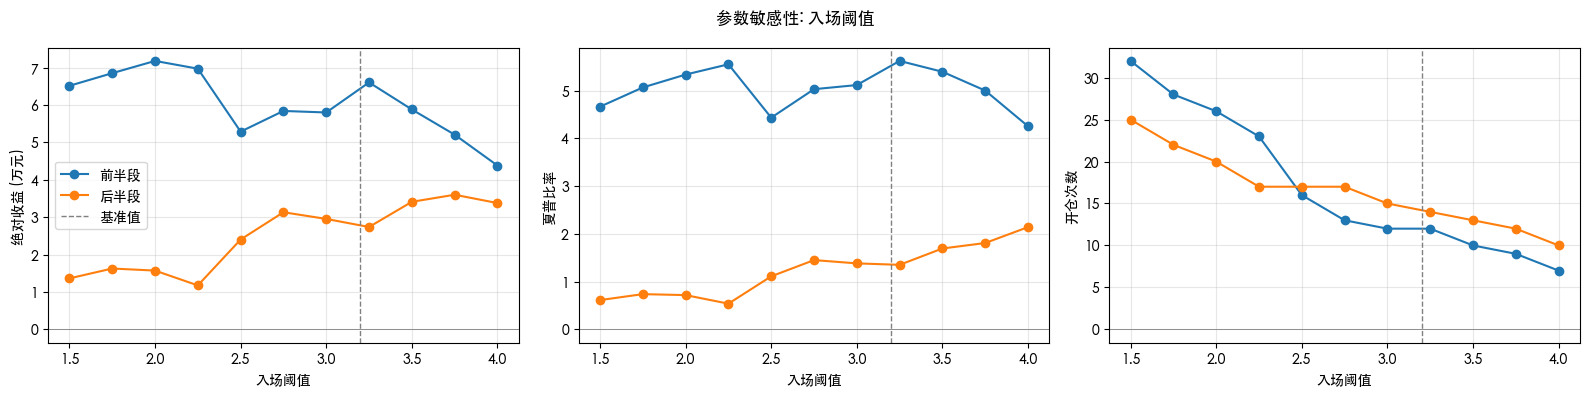

===== 出场阈值 =====
exit_z=-1.5: 前半     76,376  后半     41,907  (0s)
exit_z=-1.25: 前半     67,716  后半     33,887  (0s)
exit_z=-1.0: 前半     83,051  后半     27,248  (0s)
exit_z=-0.75: 前半     71,568  后半     26,833  (0s)
exit_z=-0.5: 前半     62,667  后半     21,655  (0s)
exit_z=-0.25: 前半     57,392  后半      7,970  (0s)
exit_z=0.0: 前半     52,561  后半     10,735  (0s)
exit_z=0.25: 前半     42,662  后半     19,232  (0s)
exit_z=0.5: 前半     38,167  后半     10,889  (0s)
exit_z=0.75: 前半     29,685  后半     -2,282  (0s)
exit_z=1.0: 前半      8,735  后半     -2,923  (0s)


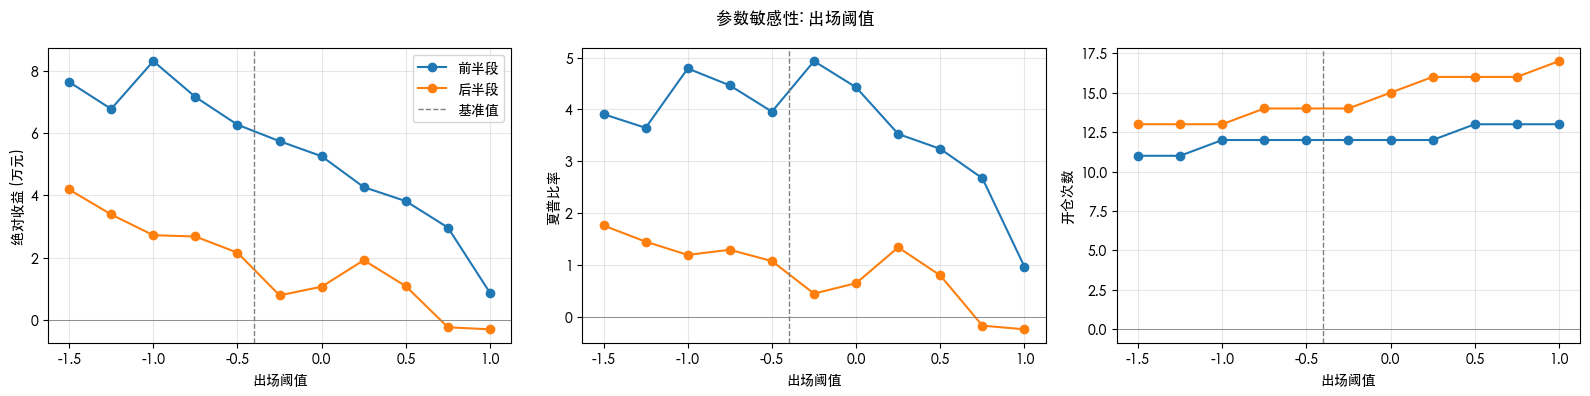

===== 滚动窗口 (分钟) =====
window=120: 前半     46,723  后半     44,506  (0s)
window=180: 前半     90,364  后半     35,168  (0s)
window=240: 前半     60,831  后半     13,191  (0s)
window=300: 前半     73,062  后半     35,955  (0s)
window=360: 前半     62,753  后半     24,374  (0s)
window=480: 前半     44,907  后半     17,314  (0s)
window=720: 前半     35,247  后半     45,187  (0s)
window=1200: 前半     27,294  后半     18,067  (0s)
window=2400: 前半      9,314  后半     14,560  (0s)


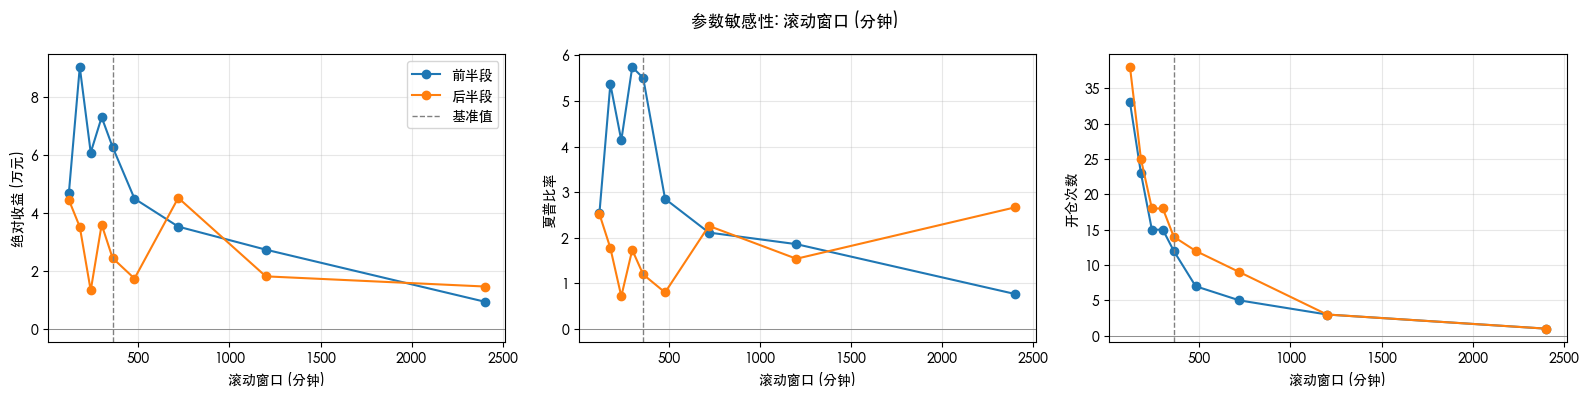

===== 重估间隔 (分钟) =====
refit_every=30: 前半     55,174  后半     17,506  (0s)
refit_every=60: 前半     54,146  后半     36,044  (0s)
refit_every=120: 前半     74,851  后半     32,592  (0s)
refit_every=180: 前半     62,753  后半     24,374  (0s)
refit_every=240: 前半     64,706  后半     20,977  (0s)
refit_every=360: 前半     53,446  后半     24,389  (0s)
refit_every=480: 前半     54,088  后半     26,648  (0s)


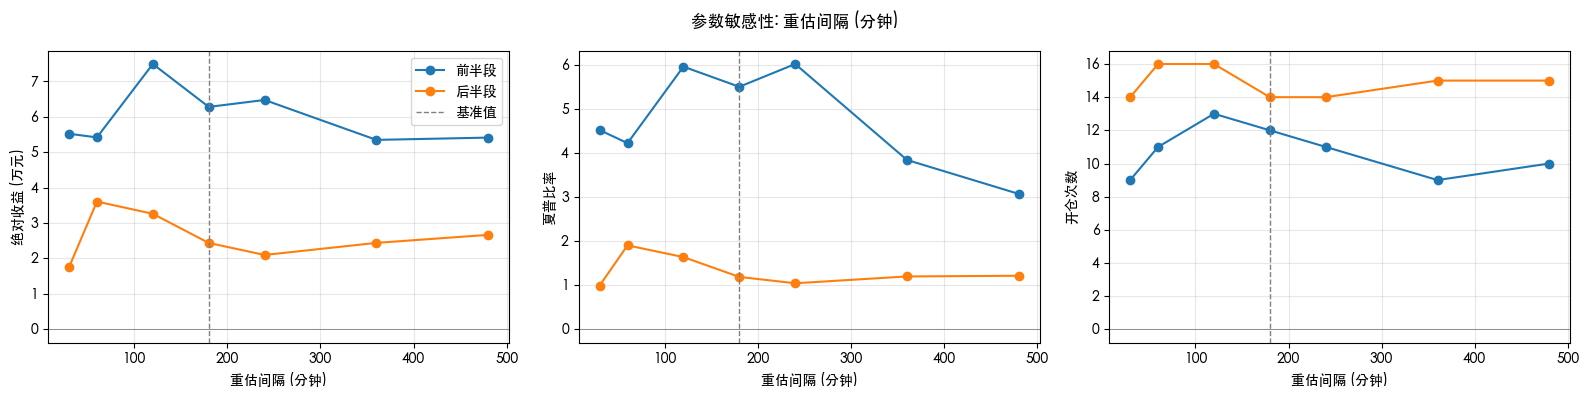

===== 交易成本倍数 =====
cost_mult=0: 前半     93,560  后半     61,010  (0s)
cost_mult=0.5: 前半     78,157  后半     42,692  (0s)
cost_mult=1.0: 前半     62,753  后半     24,374  (0s)
cost_mult=1.5: 前半     47,350  后半      6,057  (0s)
cost_mult=2.0: 前半     31,946  后半    -12,261  (0s)
cost_mult=3.0: 前半      1,139  后半    -48,897  (0s)


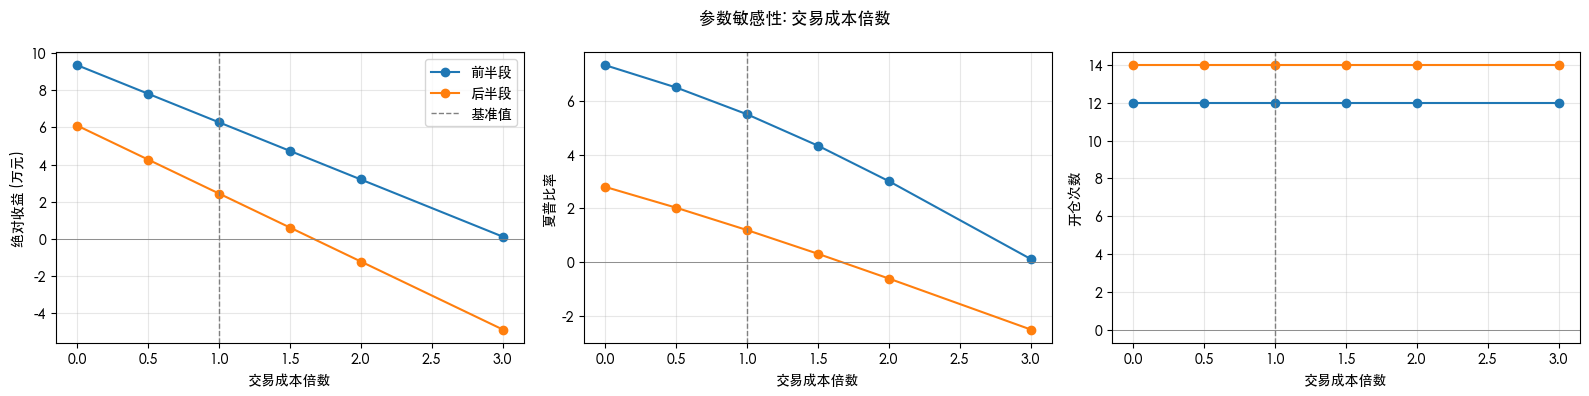

In [64]:
SWEEPS={
    # 参数名: (取值, 图上的名称, 基准值)
    'entry_z':     (np.round(np.arange(1.5, 4.01, 0.25), 2), '入场阈值', BASE['entry_z']),
    'exit_z':      (np.round(np.arange(-1.5, 1.01, 0.25), 2), '出场阈值', BASE['exit_z']),
    'window':      ([120, 180, 240, 300, 360, 480, 720, 1200, 2400], '滚动窗口 (分钟)', BASE['window']),
    'refit_every': ([30, 60, 120, 180, 240, 360, 480], '重估间隔 (分钟)', BASE['refit_every']),
    'cost_mult':   ([0, 0.5, 1.0, 1.5, 2.0, 3.0], '交易成本倍数', 1.0),
}

sens_results = {}
for name, (values, label, base_value) in SWEEPS.items():
    print(f'===== {label} =====')
    res = sweep_param(name, values)
    sens_results[name] = res
    res.to_csv(OUT_2B / f'sensitivity_{name}.csv', index=False)
    plot_sensitivity(res, name, label, base_value)

In [65]:
def sweep_grid(name_x, values_x, name_y, values_y):
    """两个参数一起变化: 每个组合分别在前半段和后半段各跑一次, 其余参数固定为 BASE"""
    rows = []
    for vy in values_y:
        for vx in values_x:
            p = dict(BASE)
            p[name_x] = vx
            p[name_y] = vy
            if p['exit_z'] > p['entry_z'] - 0.5:      # 无效组合: 留空, 图上显示为灰色
                rows.append({name_x: vx, name_y: vy})
                continue
            rows.append({name_x: vx, name_y: vy, **run_both_halves(p)})
        print(f'{name_y}={vy} 完成')
    return pd.DataFrame(rows)

def plot_heatmap(res, name_x, xlabel, name_y, ylabel, metric='收益'):
    """左图前半段, 右图后半段; 绿色为盈利, 红色为亏损, 灰色为无效或无交易; 黑框为基准参数"""
    fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
    scale = 1e4 if metric == '收益' else 1
    for ax, tag in zip(axes, ('前半段', '后半段')):
        grid = res.pivot(index=name_y, columns=name_x, values=f'{tag}_{metric}') / scale
        lim = np.nanmax(np.abs(grid.values))          # 颜色以 0 为中心对称
        cmap = plt.get_cmap('RdYlGn').copy()
        cmap.set_bad('lightgrey')
        im = ax.imshow(grid.values, cmap=cmap, vmin=-lim, vmax=lim, aspect='auto', origin='lower')
        ax.set_xticks(range(len(grid.columns)))
        ax.set_xticklabels(grid.columns)
        ax.set_yticks(range(len(grid.index)))
        ax.set_yticklabels(grid.index)

        # 每个格子标上数值
        for i in range(grid.shape[0]):
            for j in range(grid.shape[1]):
                v = grid.values[i, j]
                if not np.isnan(v):
                    ax.text(j, i, f'{v:.1f}', ha='center', va='center', fontsize=8)

        # 用黑框标出基准参数所在的格子(浮点数用 isclose 比较)
        bx = np.flatnonzero(np.isclose(grid.columns.astype(float), BASE[name_x]))
        by = np.flatnonzero(np.isclose(grid.index.astype(float), BASE[name_y]))
        if len(bx) and len(by):
            ax.add_patch(plt.Rectangle((bx[0] - 0.5, by[0] - 0.5), 1, 1,
                                       fill=False, ec='black', lw=2))

        ax.set_xlabel(xlabel)
        ax.set_ylabel(ylabel)
        ax.set_title(f'{tag}  {"绝对收益 (万元)" if metric == "收益" else "夏普比率"}')
        fig.colorbar(im, ax=ax)
    fig.tight_layout()
    fig.savefig(OUT_2B / f'heatmap_{name_x}_{name_y}_{metric}.png', dpi=150)
    plt.show()


window=120 完成
window=180 完成
window=240 完成
window=300 完成
window=360 完成
window=480 完成
window=720 完成


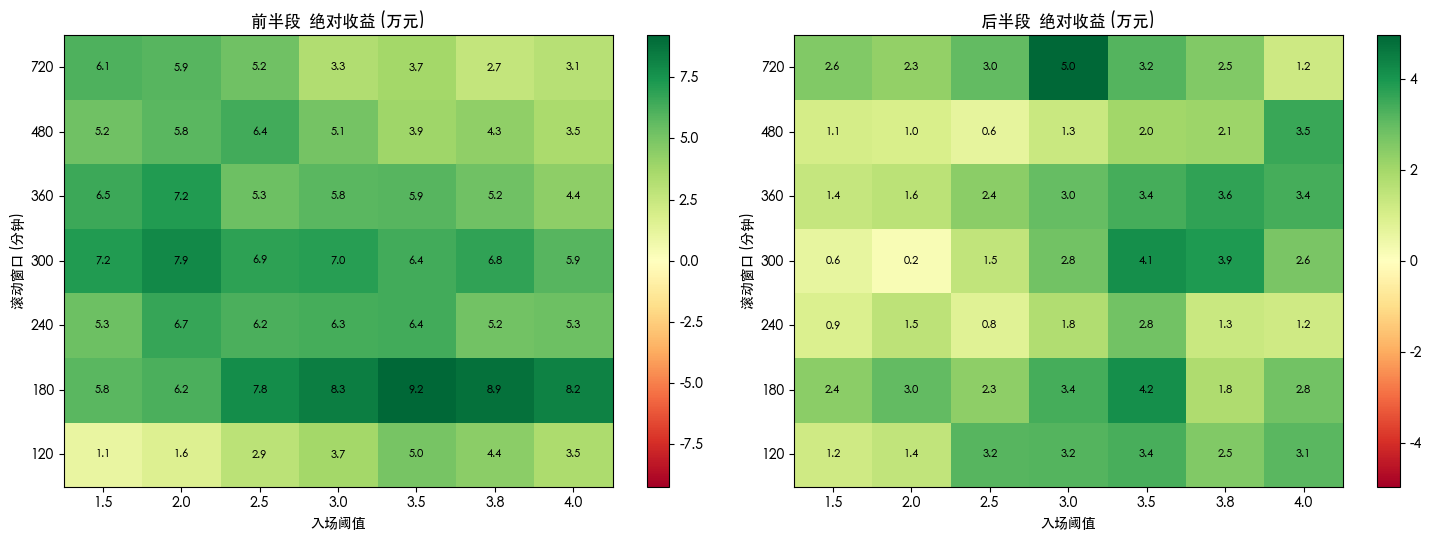

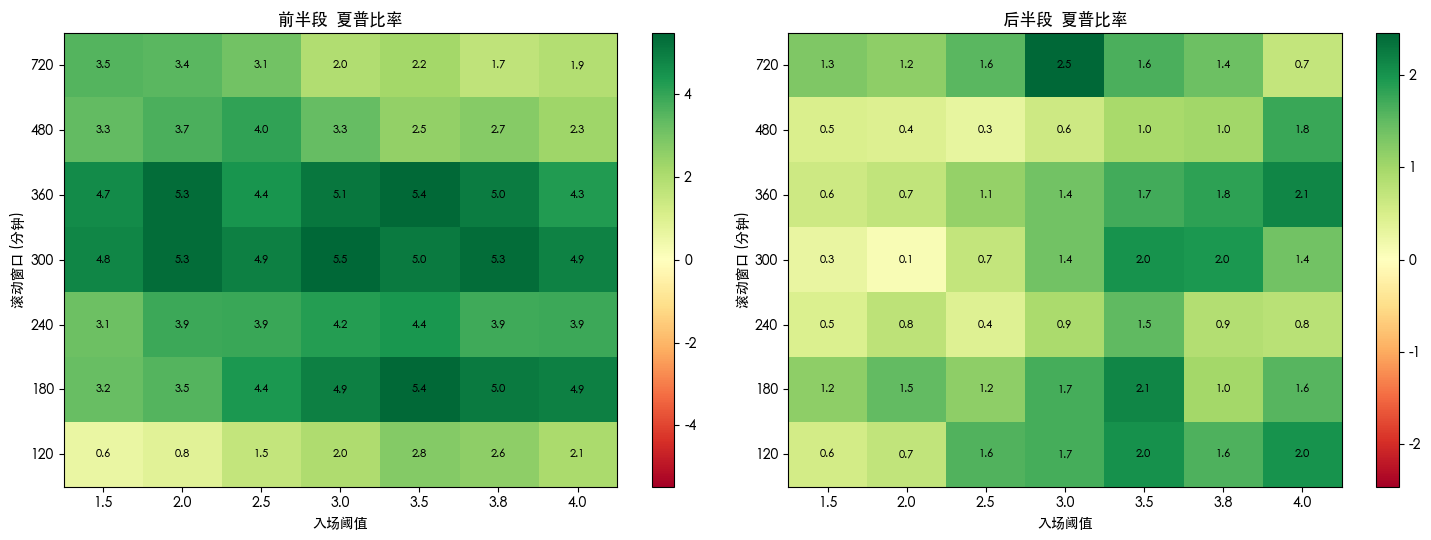

exit_z=-1.5 完成
exit_z=-1.0 完成
exit_z=-0.5 完成
exit_z=-0.4 完成
exit_z=0.0 完成
exit_z=0.5 完成
exit_z=1.0 完成


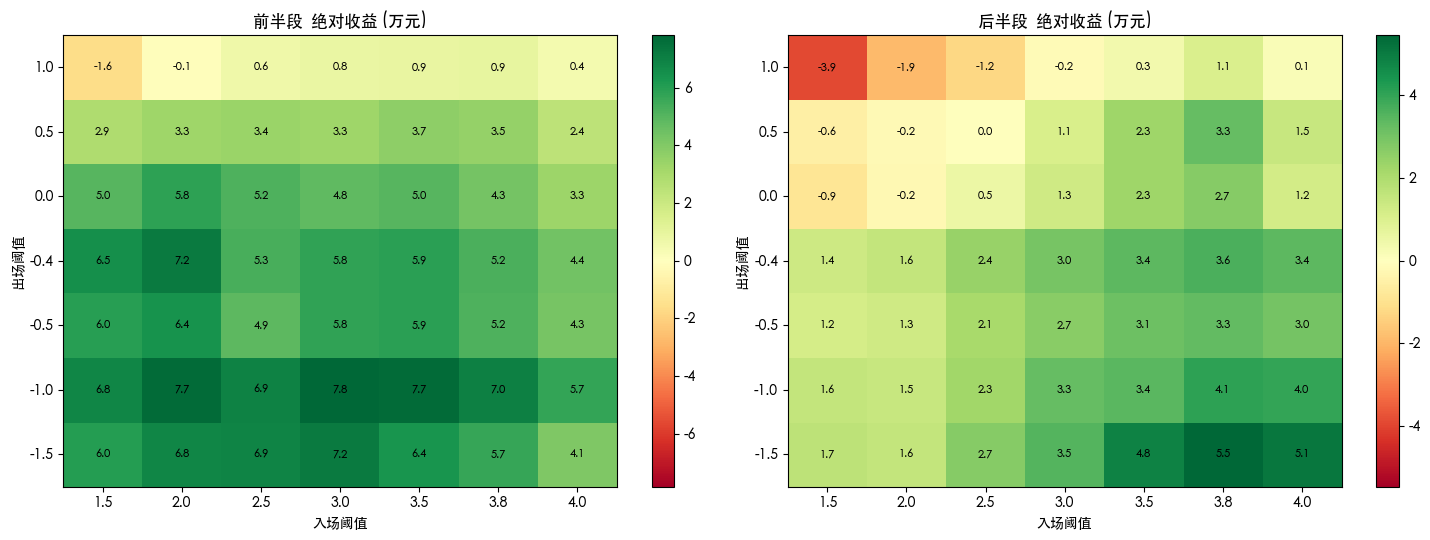

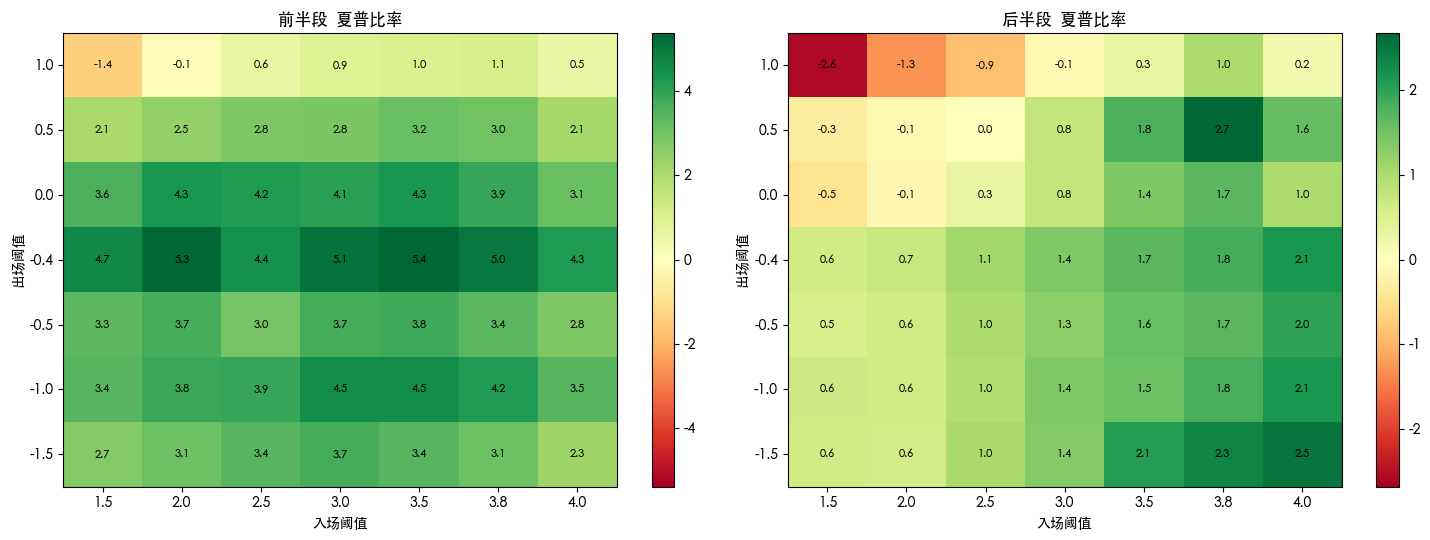

In [66]:
ENTRY_GRID = [1.5, 2.0, 2.5, 3.0, 3.5, 3.8, 4.0]
WINDOW_GRID = [120, 180, 240, 300, 360, 480, 720]
heat_entry_window = sweep_grid('entry_z', ENTRY_GRID, 'window', WINDOW_GRID)
heat_entry_window.to_csv(OUT_2B / 'heatmap_entry_window.csv', index=False)
plot_heatmap(heat_entry_window, 'entry_z', '入场阈值', 'window', '滚动窗口 (分钟)', metric='收益')
plot_heatmap(heat_entry_window, 'entry_z', '入场阈值', 'window', '滚动窗口 (分钟)', metric='夏普')

EXIT_GRID = [-1.5, -1.0, -0.5, -0.4, 0.0, 0.5, 1.0]

heat_entry_exit = sweep_grid('entry_z', ENTRY_GRID, 'exit_z', EXIT_GRID)
heat_entry_exit.to_csv(OUT_2B / 'heatmap_entry_exit.csv', index=False)
plot_heatmap(heat_entry_exit, 'entry_z', '入场阈值', 'exit_z', '出场阈值', metric='收益')
plot_heatmap(heat_entry_exit, 'entry_z', '入场阈值', 'exit_z', '出场阈值', metric='夏普')

# 风险控制: 单笔最大亏损止损、每日最大亏损止损

- 交易信号仍在每根 1 分钟 K 线收盘时生成; 止损在每一分钟内逐条检查 3 秒行情, 用复权后的买卖中间价计算浮亏;
- 单笔亏损按"回合"计算: 从开仓到全部平仓(含加仓), 包含手续费、滑点和浮亏; 触发后立即全部平仓, 要等 z 回落到出场阈值以下才允许再开仓;
- 当日亏损 = 当前资金 - 上一交易日收盘时的资金(含隔夜跳空); 触发后立即全部平仓, 当天不再开仓, 次日恢复;
- 止损定位为"保险层": 阈值参考价差的历史逆向走势分布, 只在极端行情下触发。

In [67]:
STOP_TRADE = 30_000      # 单笔止损: 满仓 8 手时约等于价差逆向 0.375 元
STOP_DAY = 25_000        # 每日止损: 满仓 8 手时约等于价差逆向 0.31 元

def risk_summary(log, trades, capital=CAPITAL):
    """在绩效指标之外, 补充: 最差回合、最差单日、止损触发次数"""
    m = pair_metrics(log, trades, capital)
    eq = log['equity']
    # 每个回合(从开仓到全部平仓)的盈亏
    held = log['lots'] > 0
    seg = (held != held.shift()).cumsum()
    worst_round = 0.0
    for _, g in log[held].groupby(seg[held]):
        i0 = log.index.get_loc(g.index[0])
        i1 = min(log.index.get_loc(g.index[-1]) + 1, len(log) - 1)
        worst_round = min(worst_round, eq.iloc[i1] - eq.iloc[i0 - 1])
    daily = eq.groupby(eq.index.normalize()).last()
    day_pnl = daily.diff()
    day_pnl.iloc[0] = daily.iloc[0] - capital
    m['最差回合(元)'] = worst_round
    m['最差单日(元)'] = day_pnl.min()
    m['单笔止损次数'] = (trades['action'] == '单笔止损').sum()
    m['每日止损次数'] = (trades['action'] == '每日止损').sum()
    return m

# 三组参数, 分别比较不止损和止损
PARAM_SETS = {
    '默认参数': dict(window=480, entry_z=2.0, exit_z=0.5),
    '夏普最优(50次)': study_sharpe.best_params,
    '夏普最优(500次)': study_sharpe_big.best_params,
}
PERIODS = {'全程': (bars, None), '前半段': (train_bars, TRAIN_START), '后半段': (bars, split_date)}

rows = []
for pname, p in PARAM_SETS.items():
    for period, (data, start) in PERIODS.items():
        for label, stops in (('不止损', {}), ('止损', dict(stop_loss_trade=STOP_TRADE, stop_loss_day=STOP_DAY))):
            log_s, tr_s, _ = run_pair_backtest_numba(data, start, None, **p, **stops)
            m = risk_summary(log_s, tr_s)
            rows.append({'参数组': pname, '区间': period, '止损': label, **m[[
                '绝对收益(元)', '夏普比率', '最大回撤', '最差回合(元)', '最差单日(元)',
                '开仓次数', '单笔止损次数', '每日止损次数']].to_dict()})

stop_compare = pd.DataFrame(rows).set_index(['参数组', '区间', '止损'])
stop_compare.to_csv(OUT_2B / 'stop_loss_compare.csv')
stop_compare.round(4)

绝对收益(元)    夏普比率    最大回撤     最差回合(元)     最差单日(元)  开仓次数  \
参数组        区间  止损                                                               
默认参数       全程  不止损   23173.1365  0.7792 -0.0042 -17914.3315 -17914.3315  52.0   
               止损    23173.1365  0.7792 -0.0042 -17914.3315 -17914.3315  52.0   
           前半段 不止损   30189.7100  2.7263 -0.0023 -11676.8835 -11676.8835  17.0   
               止损    30189.7100  2.7263 -0.0023 -11676.8835 -11676.8835  17.0   
           后半段 不止损    5908.3065  0.3719 -0.0032 -16415.1800 -16054.2795  31.0   
               止损     5908.3065  0.3719 -0.0032 -16415.1800 -16054.2795  31.0   
夏普最优(50次)  全程  不止损  103841.8360  2.7897 -0.0037 -16065.6315 -16400.0000  30.0   
               止损   103841.8360  2.7897 -0.0037 -16065.6315 -16400.0000  30.0   
           前半段 不止损   62753.0820  5.5055 -0.0023  -6687.2790  -6687.2790  12.0   
               止损    62753.0820  5.5055 -0.0023  -6687.2790  -6687.2790  12.0   
           后半段 不止损   24374.3865  1.1900 -0.0033 -21395.0280 -12467.0560  14.0   
               止损    14013.3285  0.6610 -0.0040 -31756.0860 -14938.7580  14.0   
夏普最优(500次) 全程  不止损   10191.4560  0.2589 -0.0051 -24466.2850 -20480.0000  37.0   
               止损     2107.6320  0.0577 -0.0058 -32550.1090 -19525.6600  37.0   
           前半段 不止损  116414.2380  7.1970 -0.0023  -5589.6440 -12698.2225  22.0   
               止损   116414.2380  7.1970 -0.0023  -5589.6440 -12698.2225  22.0   
           后半段 不止损   37487.8400  1.5505 -0.0045 -25955.0350 -17072.1960  25.0   
               止损    32046.2280  1.3248 -0.0051 -31396.6470 -17072.1960  25.0   

                    单笔止损次数  每日止损次数  
参数组        区间  止损                   
默认参数       全程  不止损     0.0     0.0  
               止损      0.0     0.0  
           前半段 不止损     0.0     0.0  
               止损      0.0     0.0  
           后半段 不止损     0.0     0.0  
               止损      0.0     0.0  
夏普最优(50次)  全程  不止损     0.0     0.0  
               止损      0.0     0.0  
           前半段 不止损     0.0     0.0  
               止损      0.0     0.0  
           后半段 不止损     0.0     0.0  
               止损      1.0     0.0  
夏普最优(500次) 全程  不止损     0.0     0.0  
               止损      1.0     0.0  
           前半段 不止损     0.0     0.0  
               止损      0.0     0.0  
           后半段 不止损     0.0     0.0  
               止损      1.0     0.0

## 止损阈值的敏感性: 阈值定得越紧, 收益损失多少、极端亏损少多少

In [68]:
STOP_BASE = study_sharpe.best_params          # 以夏普最优(50次)为基准参数
TRADE_GRID = [None, 10_000, 15_000, 20_000, 30_000, 40_000]
DAY_GRID = [None, 15_000, 20_000, 25_000, 35_000]

rows = []
for kind, grid in (('单笔止损', TRADE_GRID), ('每日止损', DAY_GRID)):
    for th in grid:
        stops = dict(stop_loss_trade=th) if kind == '单笔止损' else dict(stop_loss_day=th)
        for period, (data, start) in PERIODS.items():
            log_s, tr_s, _ = run_pair_backtest_numba(data, start, None, **STOP_BASE, **stops)
            m = risk_summary(log_s, tr_s)
            rows.append({'止损类型': kind, '阈值(元)': '不止损' if th is None else th, '区间': period,
                         **m[['绝对收益(元)', '夏普比率', '最大回撤', '最差回合(元)', '最差单日(元)',
                              '单笔止损次数', '每日止损次数']].to_dict()})

stop_sweep = pd.DataFrame(rows)
stop_sweep.to_csv(OUT_2B / 'stop_loss_sweep.csv', index=False)
stop_sweep.pivot_table(index=['止损类型', '阈值(元)'], columns='区间',
                       values=['绝对收益(元)', '最差回合(元)', '最差单日(元)'], sort=False).round(0)

绝对收益(元)                    最差回合(元)                    最差单日(元)  \
区间                全程      前半段      后半段       全程      前半段      后半段       全程   
止损类型 阈值(元)                                                                   
单笔止损 不止损    103842.0  62753.0  24374.0 -16066.0  -6687.0 -21395.0 -16400.0   
     10000   21943.0  31193.0  -2724.0 -12990.0 -12990.0 -11675.0 -16254.0   
     15000   79721.0  51913.0  -9269.0 -16825.0 -16430.0 -16695.0 -20935.0   
     20000   75400.0  46393.0  24332.0 -21950.0 -21950.0 -21437.0 -22396.0   
     30000  103842.0  62753.0  14013.0 -16066.0  -6687.0 -31756.0 -16400.0   
     40000  103842.0  62753.0  24374.0 -16066.0  -6687.0 -21395.0 -16400.0   
每日止损 不止损    103842.0  62753.0  24374.0 -16066.0  -6687.0 -21395.0 -16400.0   
     15000   85602.0  51913.0 -10552.0 -16430.0 -16430.0 -21395.0 -16854.0   
     20000   70361.0  46393.0  13774.0 -21950.0 -21950.0 -21395.0 -21950.0   
     25000  103842.0  62753.0  24374.0 -16066.0  -6687.0 -21395.0 -16400.0   
     35000  103842.0  62753.0  24374.0 -16066.0  -6687.0 -21395.0 -16400.0   

                              
区间              前半段      后半段  
止损类型 阈值(元)                    
单笔止损 不止损    -6687.0 -12467.0  
     10000 -12990.0 -15508.0  
     15000 -16430.0 -20334.0  
     20000 -21950.0 -12467.0  
     30000  -6687.0 -14939.0  
     40000  -6687.0 -12467.0  
每日止损 不止损    -6687.0 -12467.0  
     15000 -16430.0 -16698.0  
     20000 -21950.0 -21494.0  
     25000  -6687.0 -12467.0  
     35000  -6687.0 -12467.0

In [69]:
# 全程回测中每一次止损的明细
log_s, tr_s, _ = run_pair_backtest_numba(bars, None, None, **STOP_BASE,
                                         stop_loss_trade=STOP_TRADE, stop_loss_day=STOP_DAY)
tr_s[tr_s['action'].isin(['单笔止损', '每日止损'])]

,time,action,lots_from,lots_to,z,spread,etf,slippage


# 改进: 用卡尔曼滤波(局部水平模型)估计价差均值

前面的检验发现, 价差整体不平稳, 也不是一个固定均值的 OU 过程; 更接近 **"均值自己在随机游走 + 围绕均值的短期回复"**。
滚动 OU 每 180 分钟用最近一个窗口重新估计一次 μ, μ 是跳变的, 结果也对"在哪个时点重估"很敏感。

局部水平模型把价差拆成三部分:

$$s_t = \mu_t + x_t + v_t$$

- $\mu_t = \mu_{t-1} + \eta_t$: 均值做随机游走, 日内 $\mathrm{Var}(\eta)=q$, 跨夜 $\mathrm{Var}(\eta)=q_{night}$
- $x_t = \phi\, x_{t-1} + \varepsilon_t$: 围绕均值的偏离, 是 OU 过程(离散化后是 AR(1)), $\mathrm{Var}(\varepsilon)=r$
- $v_t$: 盘口噪声, $\mathrm{Var}(v)=h$

$\mu_t$ 和 $x_t$ 都看不到, 只能看到 $s_t$; 卡尔曼滤波每来一根 K 线做一次"预测 → 用新观测修正", 给出当前时刻 $\mu_t$ 的最优估计 $\hat\mu_t$ (只用到当前及以前的数据, 没有未来信息)。

交易规则与滚动 OU 完全相同, 只是 z 分数换成 $z_t = (s_t - \hat\mu_t) / \sigma_x$, 其中 $\sigma_x = \sqrt{r/(1-\phi^2)}$ 是偏离 $x$ 的平稳标准差。

5 个参数先用前半段做最大似然估计; 其中 $q$ 决定 $\hat\mu$ 跟随价差的快慢, 统计上最优的 $q$ 不一定交易上最优, 所以再乘一个可调的系数 `q_scale`, 和开平仓阈值一起在前半段搜索。

**可以调的地方**

| 参数 | 含义 | 本节做法 |
|---|---|---|
| `q_scale` | 均值日内随机游走的方差倍数: 越大 $\hat\mu$ 跟得越紧(偏离很快被"吃掉", 信号变少), 越小越像固定均值(趋势来了会扛单) | 与阈值一起在前半段搜索, 并做敏感性 |
| `q_night_scale` | 跨夜均值跳动的方差倍数: 越大, 开盘后越快接受新的均值水平 | 固定为 1 (最大似然值) |
| `entry_z` / `exit_z` / `full_z` | 开仓、平仓阈值和加仓尺度, 与滚动 OU 相同 | 搜索 entry、exit; full_z 固定 4 |
| `phi`、`r`、`h` | 偏离的回复速度、偏离和盘口噪声的大小 | 最大似然估计, 不调 |
| 估计样本 | 用哪段数据估计 5 个参数 | 只用前半段; 也可以改成每隔一段时间用最近数据重估 |

In [70]:
from scipy.optimize import minimize

@njit
def kalman_level(s, new_day, q, r, phi, h, q_night):
    """
    局部水平模型的卡尔曼滤波
      状态:  mu_t = mu_{t-1} + eta   (日内方差 q, 新一天第一根的方差 q_night)
             x_t  = phi * x_{t-1} + eps (方差 r)
      观测:  s_t  = mu_t + x_t + v      (方差 h)
    返回: 每根 K 线滤波后的 mu、x, 以及对数似然(用于最大似然估计)
    """
    n = s.shape[0]
    mu_f = np.empty(n)
    x_f = np.empty(n)
    m0 = s[0]                      # mu 的估计, 初始值取第一个价差
    m1 = 0.0                       # x 的估计
    P00 = 1.0                      # 协方差矩阵 [[P00, P01], [P01, P11]]; mu 初始不确定性设得较大
    P01 = 0.0
    P11 = r / (1 - phi * phi)
    loglik = 0.0
    for t in range(n):
        if t > 0:
            # ---- 预测: 根据状态方程推到这一根 ----
            qq = q_night if new_day[t] else q
            m1 = phi * m1
            P00 = P00 + qq
            P01 = phi * P01
            P11 = phi * phi * P11 + r
        # ---- 修正: 用这一根的价差更新估计 (观测矩阵 H = [1, 1]) ----
        F = P00 + 2 * P01 + P11 + h          # 预测误差的方差
        v = s[t] - m0 - m1                   # 预测误差: 实际价差 - 预测价差
        if t > 0:
            loglik += -0.5 * (np.log(2 * np.pi * F) + v * v / F)
        K0 = (P00 + P01) / F                 # 卡尔曼增益: 预测误差有多少归到 mu、多少归到 x
        K1 = (P01 + P11) / F
        m0 += K0 * v
        m1 += K1 * v
        a00 = P00 - K0 * (P00 + P01)
        a01 = P01 - K0 * (P01 + P11)
        a11 = P11 - K1 * (P01 + P11)
        P00, P01, P11 = a00, a01, a11
        mu_f[t] = m0
        x_f[t] = m1
    return mu_f, x_f, loglik

def _new_day(data):
    nd = ~data['same_day'].values.astype(bool)
    nd[0] = False
    return nd

def fit_kalman(data):
    """最大似然估计 5 个参数; 参数做变换保证方差为正、|phi| < 1"""
    s = data['spread'].values.astype(np.float64)
    nd = _new_day(data)
    unpack = lambda p: dict(q=np.exp(p[0]), r=np.exp(p[1]), phi=np.tanh(p[2]),
                            h=np.exp(p[3]), q_night=np.exp(p[4]))
    def neg_loglik(p):
        k = unpack(p)
        return -kalman_level(s, nd, k['q'], k['r'], k['phi'], k['h'], k['q_night'])[2]
    p0 = np.r_[np.log([0.01 ** 2, 0.007 ** 2]), np.arctanh(0.9), np.log([0.003 ** 2, 0.1 ** 2])]
    res = minimize(neg_loglik, p0, method='Nelder-Mead',
                   options=dict(maxiter=4000, xatol=1e-4, fatol=1e-3))
    return unpack(res.x)

KF_PARAMS = fit_kalman(train_bars)          # 只用前半段, 后半段不参与估计
_k = KF_PARAMS
print(pd.Series({
    '均值日内每分钟波动 sqrt(q)': np.sqrt(_k['q']),
    '均值跨夜跳动 sqrt(q_night)': np.sqrt(_k['q_night']),
    '偏离的 AR(1) 系数 phi': _k['phi'],
    '偏离的半衰期(分钟)': np.log(2) / -np.log(_k['phi']),
    '偏离的平稳标准差 sigma_x': np.sqrt(_k['r'] / (1 - _k['phi'] ** 2)),
    '盘口噪声 sqrt(h)': np.sqrt(_k['h']),
}).round(4))

均值日内每分钟波动 sqrt(q)        0.0069
均值跨夜跳动 sqrt(q_night)     0.0603
偏离的 AR(1) 系数 phi         0.9662
偏离的半衰期(分钟)              20.1639
偏离的平稳标准差 sigma_x         0.0250
盘口噪声 sqrt(h)             0.0073
dtype: float64


In [71]:
@njit
def _signal_bt_core(z_arr, etf_raw, etf_adj, fut_adj, roll, times, t_start, t_end,
                    entry_z, exit_z, full_z, max_lots, max_capital, capital,
                    etf_per_lot, fut_mult, etf_fee, fut_fee, etf_slip, fut_slip):
    """
    与 _backtest_core 相同的交易和记账规则(不含止损), 区别只是 z 分数由外部给出;
    z 为 NaN 的 K 线不交易。用滚动 OU 的 z 输入时, 结果与 run_pair_backtest_numba 完全一致。
    """
    n = z_arr.shape[0]
    log_idx = np.empty(n, np.int64); log_lots = np.empty(n, np.int64); log_eq = np.empty(n)
    n_log = 0
    tr_idx = np.empty(2 * n + 2, np.int64); tr_kind = np.empty(2 * n + 2, np.int64)
    tr_from = np.empty(2 * n + 2, np.int64); tr_to = np.empty(2 * n + 2, np.int64)
    tr_z = np.empty(2 * n + 2); tr_slip = np.empty(2 * n + 2)
    n_tr = 0
    equity = capital
    lots = 0
    pending_cost = 0.0
    for i in range(n):
        if i > 0 and lots != 0:
            equity += lots * (-etf_per_lot * (etf_adj[i] - etf_adj[i - 1])
                              + fut_mult * (fut_adj[i] - fut_adj[i - 1]))
        equity -= pending_cost
        pending_cost = 0.0

        z = z_arr[i]
        if np.isnan(z):
            continue
        if t_start >= 0 and times[i] < t_start:
            continue
        if t_end >= 0 and times[i] > t_end:
            if lots > 0:
                slip = lots * (etf_per_lot * etf_slip + fut_mult * fut_slip)
                pending_cost += slip + lots * (etf_per_lot * etf_adj[i] * etf_fee + fut_fee)
                tr_idx[n_tr] = i; tr_kind[n_tr] = 3; tr_from[n_tr] = lots; tr_to[n_tr] = 0
                tr_z[n_tr] = np.nan; tr_slip[n_tr] = slip; n_tr += 1
                lots = 0
            continue
        if roll[i] and lots > 0:
            rc = lots * (2 * fut_fee + 2 * fut_mult * fut_slip)
            pending_cost += rc
            tr_idx[n_tr] = i; tr_kind[n_tr] = 4; tr_from[n_tr] = lots; tr_to[n_tr] = lots
            tr_z[n_tr] = np.nan; tr_slip[n_tr] = rc; n_tr += 1

        log_idx[n_log] = i; log_lots[n_log] = lots; log_eq[n_log] = equity
        n_log += 1
        if i >= n - 2:
            continue

        target = lots
        kind = 0
        if lots > 0 and z < exit_z:
            target = 0
            kind = 2
        elif z > entry_z:
            cap_lots = int(max_capital // (etf_per_lot * etf_raw[i]))
            t = max(1, min(max_lots, cap_lots, int(max_lots * z / full_z)))
            if t > lots:
                target = t
                kind = 0 if lots == 0 else 1
        if target != lots:
            d = abs(target - lots)
            slip = d * (etf_per_lot * etf_slip + fut_mult * fut_slip)
            pending_cost += slip + d * (etf_per_lot * etf_adj[i] * etf_fee + fut_fee)
            tr_idx[n_tr] = i; tr_kind[n_tr] = kind; tr_from[n_tr] = lots; tr_to[n_tr] = target
            tr_z[n_tr] = z; tr_slip[n_tr] = slip; n_tr += 1
            lots = target
    return (log_idx[:n_log], log_lots[:n_log], log_eq[:n_log],
            tr_idx[:n_tr], tr_kind[:n_tr], tr_from[:n_tr], tr_to[:n_tr], tr_z[:n_tr], tr_slip[:n_tr], equity)

def run_signal_backtest(bars, z, mu, sigma, trade_start=None, trade_end=None,
                        entry_z=2.0, exit_z=0.5, full_z=4.0, max_lots=8, max_capital=10_000_000):
    """给定 z 分数(以及画图用的 mu、sigma)跑回测, 返回值格式与 run_pair_backtest_numba 的 log、trades 相同"""
    times = bars.index.values.astype('datetime64[ns]').view(np.int64)
    to_ns = lambda t: -1 if t is None else pd.Timestamp(t).value
    roll = (bars['fut_code'] != bars['fut_code'].shift()).values
    roll[0] = False
    li, ll, le, ti, tk, tf, tt, tz, ts, final_eq = _signal_bt_core(
        np.asarray(z, np.float64), bars['etf_last'].values.astype(np.float64),
        bars['etf_adj'].values.astype(np.float64), bars['fut_adj'].values.astype(np.float64),
        roll, times, to_ns(trade_start), to_ns(trade_end),
        float(entry_z), float(exit_z), float(full_z), int(max_lots), float(max_capital), float(max_capital),
        float(ETF_PER_LOT), float(FUT_MULT), float(ETF_FEE), float(FUT_FEE), float(ETF_SLIP), float(FUT_SLIP))
    log = pd.DataFrame({'spread': bars['spread'].values[li], 'mu': np.asarray(mu)[li],
                        'sigma_eq': np.broadcast_to(sigma, len(bars))[li], 'z': np.asarray(z)[li],
                        'lots': ll, 'equity': le}, index=bars.index[li])
    log.index.name = 'time'
    log.loc[log.index[-1], 'equity'] = final_eq
    trades = pd.DataFrame({'time': bars.index[ti], 'action': ACTIONS[tk], 'lots_from': tf, 'lots_to': tt,
                           'z': tz, 'spread': bars['spread'].values[ti], 'etf': bars['etf_last'].values[ti],
                           'slippage': ts})
    return log, trades

def kalman_signal(bars, q_scale=1.0, q_night_scale=1.0, params=None):
    """用卡尔曼滤波计算 mu、z; q_scale / q_night_scale 调节均值跟随价差的快慢"""
    k = params or KF_PARAMS
    s = bars['spread'].values.astype(np.float64)
    mu, x, _ = kalman_level(s, _new_day(bars), k['q'] * q_scale, k['r'], k['phi'], k['h'],
                            k['q_night'] * q_night_scale)
    sigma_x = np.sqrt(k['r'] / (1 - k['phi'] ** 2))
    return mu, (s - mu) / sigma_x, sigma_x

def run_kalman_backtest(bars, trade_start=None, trade_end=None, q_scale=1.0, q_night_scale=1.0, **kw):
    mu, z, sigma_x = kalman_signal(bars, q_scale, q_night_scale)
    return run_signal_backtest(bars, z, mu, sigma_x, trade_start, trade_end, **kw)

# 检查: 把滚动 OU 的 z 输入通用回测, 结果应与 run_pair_backtest_numba 完全一致
_p = dict(window=300, entry_z=3.1, exit_z=-0.5)
_log0, _tr0, _ = run_pair_backtest_numba(bars, split_date, None, **_p)
_z = pd.Series(np.nan, index=bars.index); _z[_log0.index] = _log0['z']
_mu = pd.Series(np.nan, index=bars.index); _mu[_log0.index] = _log0['mu']
_log1, _tr1 = run_signal_backtest(bars, _z.values, _mu.values, np.nan, split_date, None,
                                  entry_z=3.1, exit_z=-0.5)
print('核对 期末资金:', round(_log0['equity'].iloc[-1], 2), round(_log1['equity'].iloc[-1], 2),
      '| 交易笔数:', len(_tr0), len(_tr1))

核对 期末资金: 10036330.19 10036330.19 | 交易笔数: 60 60


In [72]:
# 在前半段搜索 q_scale、entry_z、exit_z (目标: 夏普比率)
# entry_z、exit_z 的范围与滚动 OU 的夏普最优搜索(study_sharpe)相同, 保证比较公平;
# 放宽范围(例如 exit_z 到 -2)后前半段夏普更高, 但后半段明显变差, 属于过拟合
def make_kalman_objective(penalty=-10.0, exit_low=-0.5, entry_high=4.0):
    def objective(trial):
        q_scale = trial.suggest_float('q_scale', 1e-3, 1.0, log=True)
        entry_z = trial.suggest_float('entry_z', 1.0, entry_high, step=0.1)
        exit_z = trial.suggest_float('exit_z', exit_low, 1.5, step=0.1)
        if exit_z > entry_z - 0.3:
            return penalty
        log, trades = run_kalman_backtest(train_bars, TRAIN_START, None,
                                          q_scale=q_scale, entry_z=entry_z, exit_z=exit_z)
        if len(trades) == 0:
            return penalty
        m = pair_metrics(log, trades, CAPITAL)
        if m['开仓次数'] < MIN_OPENS:
            return penalty
        for k in ('绝对收益(元)', '夏普比率', '最大回撤', '开仓次数'):
            trial.set_user_attr(k, float(m[k]))
        return float(m['夏普比率'])
    return objective

study_kf = optuna.create_study(direction='maximize', sampler=optuna.samplers.TPESampler(seed=42))
study_kf.optimize(make_kalman_objective(), n_trials=300, show_progress_bar=True)
KF_BEST = study_kf.best_params
print('卡尔曼 夏普最优:', {k: round(v, 4) for k, v in KF_BEST.items()}, f'夏普 {study_kf.best_value:.2f}')

# 前半段(搜索用过) / 后半段(没见过) 对比
OU_BEST = study_sharpe.best_params if 'study_sharpe' in globals() else dict(window=300, entry_z=3.1, exit_z=-0.5)
runs = {
    '滚动OU 夏普最优': lambda d, ts: run_pair_backtest_numba(d, ts, None, **OU_BEST)[:2],
    '卡尔曼 夏普最优': lambda d, ts: run_kalman_backtest(d, ts, None, **KF_BEST),
}
rows = []
for name, f in runs.items():
    row = {'方法': name}
    for tag, d, ts in (('前半', train_bars, TRAIN_START), ('后半', bars, split_date)):
        m = pair_metrics(*f(d, ts), CAPITAL)
        for k in ('绝对收益(元)', '夏普比率', '最大回撤', '开仓次数'):
            row[f'{tag}_{k}'] = m[k]
    rows.append(row)
kf_compare = pd.DataFrame(rows).set_index('方法')
display(kf_compare.round(3))

# 稳健性: 前半段排名前 10 的参数在后半段的表现
top = (study_kf.trials_dataframe().query('value > -10')
       .sort_values('value', ascending=False).head(10))
top['后半收益'] = [pair_metrics(*run_kalman_backtest(bars, split_date, None, q_scale=a, entry_z=b, exit_z=c), CAPITAL)['绝对收益(元)']
                 for a, b, c in zip(top['params_q_scale'], top['params_entry_z'], top['params_exit_z'])]
display(top[['params_q_scale', 'params_entry_z', 'params_exit_z', 'value', 'user_attrs_绝对收益(元)', '后半收益']].round(4))
print(f"前 10 组参数在后半段: 收益中位 {top['后半收益'].median():,.0f} 元, 为正 {(top['后半收益'] > 0).sum()}/10")
kf_compare.to_csv(OUT_2B / 'kalman_vs_ou.csv', encoding='utf-8-sig')

  0%|          | 0/300 [00:00<?, ?it/s]

卡尔曼 夏普最优: {'q_scale': 0.025, 'entry_z': 3.9, 'exit_z': -0.5} 夏普 5.64


,前半_绝对收益(元),前半_夏普比率,前半_最大回撤,前半_开仓次数,后半_绝对收益(元),后半_夏普比率,后半_最大回撤,后半_开仓次数
方法,,,,,,,,
滚动OU 夏普最优,62753.082,5.506,-0.002,12.0,24374.386,1.190,-0.003,14.0
卡尔曼 夏普最优,74156.868,5.641,-0.002,14.0,42608.108,1.977,-0.003,16.0


,params_q_scale,params_entry_z,params_exit_z,value,user_attrs_绝对收益(元),后半收益
278,0.0260,3.9,-0.5,5.6409,74156.8685,42608.1080
279,0.0261,3.9,-0.5,5.6409,74156.8685,42608.1080
227,0.0250,3.9,-0.5,5.6409,74156.8685,42608.1080
273,0.0259,3.9,-0.5,5.6409,74156.8685,42608.1080
232,0.0266,3.9,-0.4,5.6218,70197.5115,60696.2120
263,0.0267,3.9,-0.4,5.6218,70197.5115,60696.2120
226,0.0247,3.9,-0.5,5.6171,73806.7460,41138.0765
285,0.0247,3.9,-0.5,5.6171,73806.7460,42608.1080
274,0.0262,3.8,-0.5,5.5447,72546.7740,41138.0765
249,0.0237,3.9,-0.4,5.4817,70041.4320,38148.0200


前 10 组参数在后半段: 收益中位 42,608 元, 为正 10/10


,均值每日波动,前半收益,前半夏普,前半开仓,后半收益,后半夏普,后半开仓
q_scale,,,,,,,
1.000,0.107,0.000,NaN,0.0,0.000,NaN,0.0
0.300,0.059,8379.404,2.181,1.0,-10245.902,-3.094,4.0
0.100,0.034,37434.936,3.648,6.0,38086.237,3.261,12.0
0.030,0.019,61956.957,5.014,12.0,52948.862,2.573,17.0
0.010,0.011,79339.813,4.957,14.0,26575.858,1.166,15.0
0.003,0.006,82786.008,4.778,14.0,37334.748,1.504,15.0
0.001,0.003,69570.758,3.840,12.0,30601.934,1.166,14.0


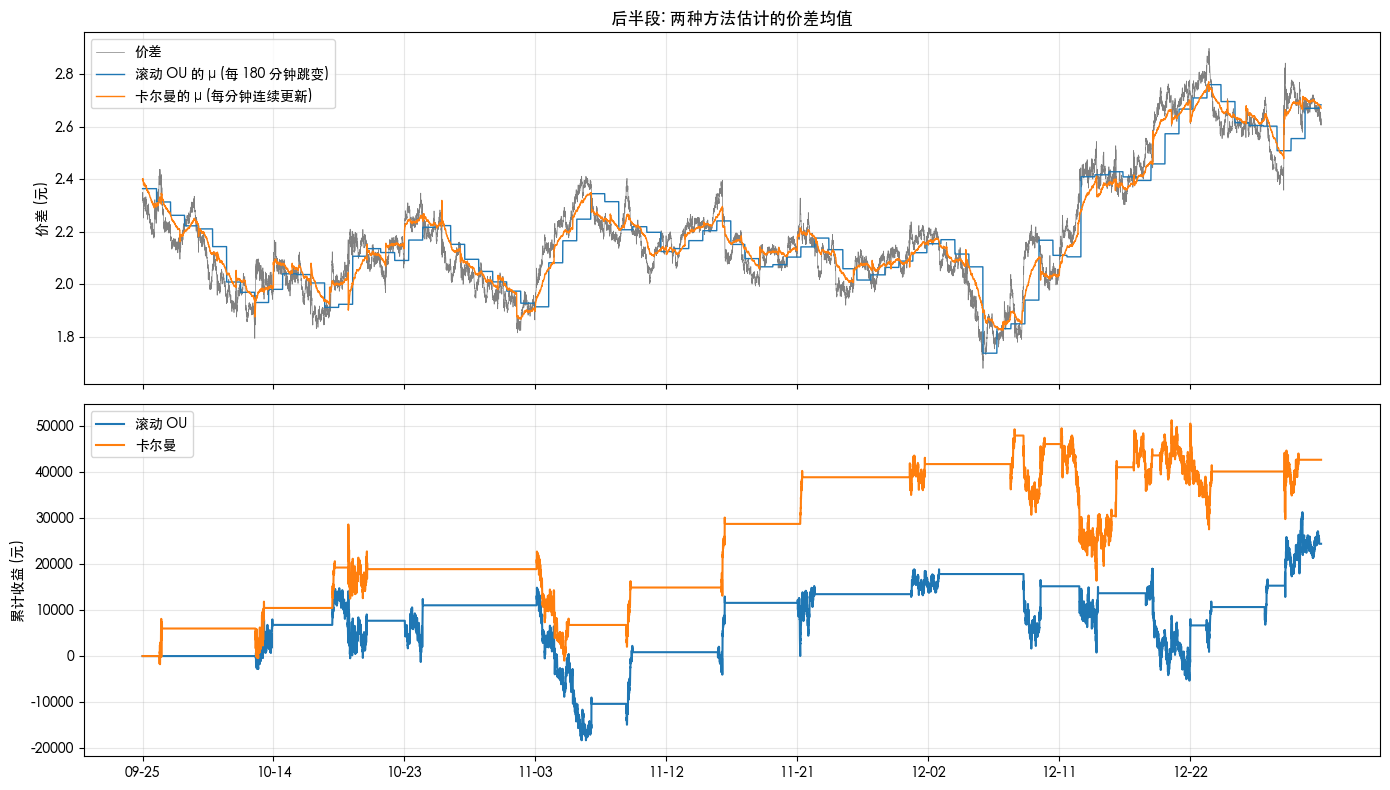

In [73]:
# q_scale 的敏感性: 固定开平仓阈值, 看均值跟得快/慢对前后半段的影响
Q_GRID = [1.0, 0.3, 0.1, 0.03, 0.01, 0.003, 0.001]
_p = {k: v for k, v in KF_BEST.items() if k != 'q_scale'}
rows = []
for qs in Q_GRID:
    r = {'q_scale': qs, '均值每日波动': np.sqrt(KF_PARAMS['q'] * qs * 240)}
    for tag, d, ts in (('前半', train_bars, TRAIN_START), ('后半', bars, split_date)):
        m = pair_metrics(*run_kalman_backtest(d, ts, None, q_scale=qs, **_p), CAPITAL)
        r[f'{tag}收益'] = m['绝对收益(元)']; r[f'{tag}夏普'] = m['夏普比率']; r[f'{tag}开仓'] = m['开仓次数']
    rows.append(r)
q_sens = pd.DataFrame(rows).set_index('q_scale')
display(q_sens.round(3))

# 图: 后半段价差、两种均值估计、资金曲线
log_ou, _ = run_pair_backtest_numba(bars, split_date, None, **OU_BEST)[:2]
log_kf, _ = run_kalman_backtest(bars, split_date, None, **KF_BEST)
x = np.arange(len(log_kf))
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(14, 8), sharex=True)
ax1.plot(x, log_kf['spread'], lw=0.5, color='gray', label='价差')
ax1.plot(x, log_ou['mu'].reindex(log_kf.index), lw=1.0, label='滚动 OU 的 μ (每 180 分钟跳变)')
ax1.plot(x, log_kf['mu'], lw=1.0, label='卡尔曼的 μ (每分钟连续更新)')
ax1.set_ylabel('价差 (元)'); ax1.legend(loc='upper left'); ax1.grid(alpha=0.3)
ax1.set_title('后半段: 两种方法估计的价差均值')
ax2.plot(x, log_ou['equity'].reindex(log_kf.index) - CAPITAL, label='滚动 OU')
ax2.plot(x, log_kf['equity'] - CAPITAL, label='卡尔曼')
ax2.set_ylabel('累计收益 (元)'); ax2.legend(loc='upper left'); ax2.grid(alpha=0.3)
date_ticks(ax2, log_kf.index)
plt.tight_layout()
plt.savefig(OUT_2B / 'kalman_vs_ou.png', dpi=120)
plt.show()